# Informe EDA + base para Visual Analytics — CrimAnalyzer

**Curso:** Ciencia de Datos / Visual Analytics  
**Fecha de entrega:** 19/09/2026  
**Propósito:** construir un análisis exploratorio de datos (EDA/AED) reproducible que sirva como evidencia para el informe y como puente hacia la propuesta final de Visual Analytics.

> **Paper base:** *CrimAnalyzer: Understanding Crime Patterns in Sao Paulo City*. El artículo plantea la necesidad de explorar patrones criminales **espaciales y temporales**, especialmente a escala local, y propone tareas de análisis sobre patrones de crimen, evolución temporal y hotspots. El conjunto descrito por los autores contiene registros de 2000–2004 luego de excluir 2005–2006 por inconsistencias; cada registro incluye sitio censal, tipo de crimen y fecha/hora. fileciteturn0file0L269-L298

## Cómo usar este notebook
1. Coloca tu dataset en la misma carpeta que este `.ipynb` o indica su ruta en `DATA_PATH`.
2. Ejecuta las celdas en orden.
3. Revisa la salida de **1. Configuración** y ajusta los nombres de columnas del bloque `CONFIG`.
4. Define tus **3 hipótesis** en la sección correspondiente.
5. Guarda las figuras/tablas generadas para incorporarlas al informe.
6. No borres las celdas de diagnóstico: sirven como evidencia de calidad y reproducibilidad.

El notebook funciona con **CSV, Excel y JSON**. También intenta detectar automáticamente la extensión del archivo.


In [13]:
# ============================================================
# 0. INSTALACIÓN / IMPORTACIONES
# ============================================================
# Ejecuta esta celda si te faltan paquetes:
# %pip install pandas numpy scipy matplotlib seaborn scikit-learn openpyxl statsmodels

from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import NMF
from sklearn.metrics import mean_squared_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid", context="notebook")

OUTPUT_DIR = Path("salidas_informe")
FIG_DIR = OUTPUT_DIR / "figuras"
TABLE_DIR = OUTPUT_DIR / "tablas"

OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
TABLE_DIR.mkdir(exist_ok=True)

print("Entorno listo.")
print("Carpeta de resultados:", OUTPUT_DIR.resolve())


Entorno listo.
Carpeta de resultados: C:\Users\aleax\Desktop\data_science_final\salidas_informe


## 1. Configuración

La parte que depende de tu dataset se concentra aquí. **No inventes nombres de variables**: primero ejecuta la celda siguiente para inspeccionar las columnas y luego vuelve a esta configuración.

### Variables recomendadas para un dataset como el del paper
- `DATE_COL`: fecha/hora del hecho.
- `CRIME_COL`: tipo de crimen.
- `SITE_COL`: unidad espacial (sitio, zona, distrito, etc.).
- `LAT_COL` / `LON_COL`: coordenadas, si existen.
- `TARGET_COL`: variable principal que quieras comparar para alguna hipótesis, si aplica.

Las hipótesis propuestas abajo están inspiradas en las tareas analíticas del paper: patrones de crimen según el espacio, evolución temporal y concentración/hotspots. fileciteturn0file0L299-L339


In [14]:
# ============================================================
# CONFIG — EDITA SOLO ESTA CELDA
# ============================================================

DATA_PATH = "Crimes_-_2001_to_Present_20260911.csv"   # Ej.: "crime.csv", "datos.xlsx", "registros.json"

# Si tu archivo tiene varias hojas de Excel:
EXCEL_SHEET = 0

# Nombres de columnas: escríbelos exactamente como aparecen en df.columns
# ID	Case Number	Date	Block	IUCR	Primary Type	Description	Location Description	Arrest	Domestic	Beat	District	Ward	Community Area	FBI Code	X Coordinate	Y Coordinate	Year	Updated On	Latitude	Longitude	Location
DATE_COL = "Date"                # Ej.: "Date"
CRIME_COL = "Primary Type"               # Ej.: "Crime_Type"
SITE_COL = "Location Description"                # Ej.: "Site"
LAT_COL = "Latitude"                 # Ej.: "Latitude"
LON_COL = "Longitude"                 # Ej.: "Longitude"

# Opcional: identificador único de registro
ID_COL = None

# Tratamiento de valores especiales que representan faltantes
MISSING_TOKENS = ["?", "NA", "N/A", "na", "null", "NULL", "", "Unknown", "unknown"]

# Umbral orientativo para marcar missingness relevante
MISSING_ALERT_PCT = 5.0

# Semilla para reproducibilidad
RANDOM_STATE = 42

print("Config cargada.")


Config cargada.


In [15]:
# ============================================================
# 2. DESCUBRIMIENTO / CARGA AUTOMÁTICA DEL DATASET
# ============================================================

def auto_find_data():
    candidates = []
    for ext in ["*.csv", "*.xlsx", "*.xls", "*.json"]:
        candidates.extend(Path(".").glob(ext))
    return sorted(candidates)

def load_dataset(path, excel_sheet=0):
    path = Path(path)
    if not path.exists():
        print("No se encontró DATA_PATH:", path)
        print("\nArchivos de datos detectados en la carpeta:")
        for p in auto_find_data():
            print(" -", p)
        raise FileNotFoundError(
            "Cambia DATA_PATH en la celda CONFIG por el nombre/ruta real de tu dataset."
        )

    suffix = path.suffix.lower()
    if suffix == ".csv":
        # Intento estándar; luego latin-1 si hiciera falta
        try:
            return pd.read_csv(path)
        except UnicodeDecodeError:
            return pd.read_csv(path, encoding="latin-1")
    elif suffix in [".xlsx", ".xls"]:
        return pd.read_excel(path, sheet_name=excel_sheet)
    elif suffix == ".json":
        return pd.read_json(path)
    else:
        raise ValueError(f"Formato no soportado: {suffix}")

df_raw = load_dataset(DATA_PATH, EXCEL_SHEET)

print("Dataset cargado correctamente.")
print("Filas:", f"{df_raw.shape[0]:,}")
print("Columnas:", df_raw.shape[1])
display(df_raw.head())


Dataset cargado correctamente.
Filas: 8,636,476
Columnas: 22


,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
0,14315255,JK398108,09/03/2026 12:00:00 AM,070XX S FAIRFIELD AVE,0498,BATTERY,"AGG. DOMESTIC BATTERY - HANDS, FISTS, FEET, SERIOUS INJURY",RESIDENCE,False,True,831,8.0,17.0,66.0,04B,1159260.0,1857750.0,2026,09/10/2026 03:53:03 PM,41.765386,-87.691824,"(41.765385733, -87.691823541)"
1,14315392,JK398216,09/03/2026 12:00:00 AM,068XX S WESTERN AVE,1310,CRIMINAL DAMAGE,TO PROPERTY,DAY CARE CENTER,False,False,832,8.0,16.0,66.0,14,1161556.0,1859189.0,2026,09/10/2026 03:53:03 PM,41.769287,-87.683368,"(41.769287256, -87.683368075)"
2,14315233,JK398112,09/03/2026 12:00:00 AM,0000X E PEARSON ST,0560,ASSAULT,SIMPLE,RESIDENCE,False,False,1833,18.0,42.0,8.0,08A,1176455.0,1906042.0,2026,09/10/2026 03:53:03 PM,41.897534,-87.627344,"(41.89753369, -87.627343939)"
3,14315892,JK398470,09/03/2026 12:00:00 AM,009XX W WELLINGTON AVE,0312,ROBBERY,ARMED - KNIFE / CUTTING INSTRUMENT,CTA TRAIN,False,False,1933,19.0,44.0,6.0,03,1169423.0,1920111.0,2026,09/10/2026 03:53:03 PM,41.936296,-87.652761,"(41.936295672, -87.652761369)"
4,14315904,JK398881,09/03/2026 12:00:00 AM,036XX N HAMLIN AVE,0486,BATTERY,DOMESTIC BATTERY SIMPLE,RESIDENCE,True,True,1732,17.0,30.0,16.0,08B,1150412.0,1923945.0,2026,09/10/2026 03:53:03 PM,41.947209,-87.722529,"(41.947209355, -87.722528621)"


## 3. Inventario inicial

Esta sección sirve como evidencia para:
- formato original,
- tamaño,
- granularidad,
- nombres de atributos,
- tipos de datos preliminares,
- primeras señales de calidad.

No se debe transformar el dataset original todavía; se conserva como `df_raw`.


In [16]:
# ============================================================
# 3.1 ESTRUCTURA GENERAL
# ============================================================
print("TIPOS DE DATOS")
display(df_raw.dtypes.to_frame("dtype"))

print("\nRESUMEN")
summary0 = pd.DataFrame({
    "filas": [df_raw.shape[0]],
    "columnas": [df_raw.shape[1]],
    "duplicados_totales": [df_raw.duplicated().sum()]
})
display(summary0)

print("\nMEMORIA")
print(f"{df_raw.memory_usage(deep=True).sum()/1024**2:.2f} MB")

print("\nMUESTRA ALEATORIA")
display(df_raw.sample(min(10, len(df_raw)), random_state=RANDOM_STATE))


TIPOS DE DATOS


,dtype
ID,int64
Case Number,str
Date,str
Block,str
IUCR,str
Primary Type,str
Description,str
Location Description,str
Arrest,bool
Domestic,bool



RESUMEN


,filas,columnas,duplicados_totales
0,8636476,22,0



MEMORIA
5885.23 MB

MUESTRA ALEATORIA


,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
5276088,6182400,HP271621,04/06/2008 11:00:00 AM,005XX N RUSH ST,0820,THEFT,$500 AND UNDER,PARKING LOT/GARAGE(NON.RESID.),False,False,1834,18.0,42.0,8.0,06,1177015.0,1903707.0,2008,02/10/2018 03:50:01 PM,41.891114,-87.625358,"(41.891113672, -87.625357917)"
8508832,1476641,G208013,04/12/2001 11:05:00 AM,023XX W DEVON AV,0420,BATTERY,AGGRAVATED:KNIFE/CUTTING INSTR,STREET,True,True,2412,24.0,NaN,NaN,04B,1159615.0,1942473.0,2001,08/17/2015 03:03:40 PM,41.997866,-87.688188,"(41.997866116, -87.688187918)"
5112571,6432310,HP513832,08/14/2008 10:25:00 PM,060XX W LAWRENCE AVE,1320,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,1622,16.0,38.0,15.0,14,1135305.0,1931282.0,2008,02/10/2018 03:50:01 PM,41.967625,-87.777884,"(41.967624803, -87.777883882)"
4549986,7312532,HS115323,01/10/2010 09:00:00 PM,022XX N LOREL AVE,0313,ROBBERY,ARMED: OTHER DANGEROUS WEAPON,RESIDENCE PORCH/HALLWAY,False,False,2515,25.0,37.0,19.0,03,1140354.0,1914282.0,2010,02/10/2018 03:50:01 PM,41.920884,-87.759737,"(41.920883829, -87.759737207)"
1882841,11504814,JB502862,11/04/2018 07:50:00 AM,0000X W TERMINAL ST,0860,THEFT,RETAIL THEFT,AIRPORT EXTERIOR - NON-SECURE AREA,False,False,1653,16.0,41.0,76.0,06,1101811.0,1934419.0,2018,11/22/2018 04:00:54 PM,41.976763,-87.900984,"(41.976762981, -87.900983721)"
6101969,4746724,HM356243,05/17/2006 01:10:00 PM,057XX W NEWPORT AVE,0320,ROBBERY,STRONGARM - NO WEAPON,SIDEWALK,False,False,1633,16.0,38.0,15.0,03,1137568.0,1922360.0,2006,02/10/2018 03:50:01 PM,41.943101,-87.769779,"(41.943101413, -87.769778646)"
4429672,7497889,HS301549,05/11/2010 03:30:00 AM,013XX E 70TH ST,0281,CRIM SEXUAL ASSAULT,NON-AGGRAVATED,SIDEWALK,True,True,321,3.0,5.0,69.0,02,1186209.0,1858853.0,2010,02/10/2018 03:50:01 PM,41.767818,-87.593013,"(41.767818469, -87.593012964)"
8146739,1927177,HH105031,01/03/2002 04:50:33 PM,008XX N MICHIGAN AV,0820,THEFT,$500 AND UNDER,DEPARTMENT STORE,True,False,1833,18.0,NaN,NaN,06,1177338.0,1906160.0,2002,02/28/2018 03:56:25 PM,41.897838,-87.624097,"(41.897837503, -87.624097243)"
1546238,11989948,JD162476,02/23/2020 04:30:00 PM,027XX W NORTH SHORE AVE,0486,BATTERY,DOMESTIC BATTERY SIMPLE,APARTMENT,False,True,2412,24.0,50.0,2.0,08B,1156639.0,1944333.0,2020,09/07/2021 03:41:02 PM,42.003031,-87.699085,"(42.003031036, -87.699084903)"
1692854,11968039,JD135128,07/29/2019 12:00:00 AM,012XX N LA SALLE DR,2826,OTHER OFFENSE,HARASSMENT BY ELECTRONIC MEANS,RESIDENCE,False,True,1821,18.0,2.0,8.0,26,1174911.0,1908554.0,2019,09/07/2021 03:41:02 PM,41.904461,-87.632939,"(41.904461469, -87.63293948)"


In [17]:
# ============================================================
# 3.2 NORMALIZACIÓN BÁSICA DE TEXTO DE COLUMNAS
# ============================================================
df = df_raw.copy()

# Mantener nombres originales en una copia
original_columns = df.columns.tolist()

# Limpiar espacios accidentales en nombres
df.columns = [str(c).strip() for c in df.columns]

print("Columnas:")
for c in df.columns:
    print(" -", repr(c))


Columnas:
 - 'ID'
 - 'Case Number'
 - 'Date'
 - 'Block'
 - 'IUCR'
 - 'Primary Type'
 - 'Description'
 - 'Location Description'
 - 'Arrest'
 - 'Domestic'
 - 'Beat'
 - 'District'
 - 'Ward'
 - 'Community Area'
 - 'FBI Code'
 - 'X Coordinate'
 - 'Y Coordinate'
 - 'Year'
 - 'Updated On'
 - 'Latitude'
 - 'Longitude'
 - 'Location'


### 3.3 Asigna las columnas

Después de mirar `df.columns`, actualiza `DATE_COL`, `CRIME_COL`, `SITE_COL` y, si existen, las coordenadas.


In [18]:
# ============================================================
# VALIDACIÓN DE CONFIGURACIÓN
# ============================================================

def validate_col(col, name, required=False):
    if col is None:
        print(f"{name}: no configurada")
        if required:
            raise ValueError(f"Debes configurar {name}.")
        return
    if col not in df.columns:
        raise ValueError(f"{name}={col!r} no existe en las columnas.")
    print(f"{name}: {col}")

validate_col(DATE_COL, "DATE_COL")
validate_col(CRIME_COL, "CRIME_COL")
validate_col(SITE_COL, "SITE_COL")
validate_col(LAT_COL, "LAT_COL")
validate_col(LON_COL, "LON_COL")
validate_col(ID_COL, "ID_COL")


DATE_COL: Date
CRIME_COL: Primary Type
SITE_COL: Location Description
LAT_COL: Latitude
LON_COL: Longitude
ID_COL: no configurada


# 4. Data Wrangling y calidad de datos

El paper destaca un ejemplo importante de control de calidad: los autores detectaron que 2005 y 2006 no eran consistentes con los años previos y, después de revisar la situación, trabajaron con 2000–2004. fileciteturn0file0L269-L281

En tu dataset **no se eliminarán años o registros automáticamente por parecer extraños**. Primero se diagnostican y luego se documenta la decisión.


In [19]:
# ============================================================
# 4.1 VALORES CODIFICADOS COMO FALTANTES
# ============================================================
df_work = df.copy()

for col in df_work.select_dtypes(include="object").columns:
    df_work[col] = df_work[col].replace(MISSING_TOKENS, np.nan)

missing = pd.DataFrame({
    "atributo": df_work.columns,
    "nulos_cantidad": df_work.isna().sum().values,
})
missing["nulos_pct"] = 100 * missing["nulos_cantidad"] / len(df_work)
missing["alerta"] = np.where(missing["nulos_pct"] >= MISSING_ALERT_PCT, "Revisar", "")
missing = missing.sort_values("nulos_pct", ascending=False)

display(missing)
missing.to_csv(TABLE_DIR / "01_nulos_por_atributo.csv", index=False)


,atributo,nulos_cantidad,nulos_pct,alerta
12,Ward,614811,7.118772,Revisar
13,Community Area,613722,7.106162,Revisar
21,Location,99997,1.157845,
16,Y Coordinate,99997,1.157845,
20,Longitude,99997,1.157845,
19,Latitude,99997,1.157845,
15,X Coordinate,99997,1.157845,
7,Location Description,16641,0.192683,
11,District,47,0.000544,
4,IUCR,0,0.000000,


In [20]:
# ============================================================
# 4.2 DUPLICADOS
# ============================================================
dup_count = df_work.duplicated().sum()
dup_pct = 100 * dup_count / len(df_work)

print(f"Duplicados exactos: {dup_count:,} ({dup_pct:.2f}%)")

if ID_COL is not None:
    duplicated_ids = df_work[ID_COL].duplicated(keep=False).sum()
    print(f"Registros con ID repetido: {duplicated_ids:,}")


Duplicados exactos: 0 (0.00%)


In [21]:
# ============================================================
# 4.3 CONVERSIÓN DE FECHA / HORA
# ============================================================
if DATE_COL is not None:
    parsed_date_col = DATE_COL + "_parsed"
    df_work[parsed_date_col] = pd.to_datetime(
        df_work[DATE_COL], errors="coerce"
    )
    invalid_dates = int(df_work[parsed_date_col].isna().sum())
    total_rows = len(df_work)
    invalid_pct = 100 * invalid_dates / total_rows if total_rows else 0
    print(f"Fechas no interpretables: {invalid_dates:,} ({invalid_pct:.2f}%)")

    if total_rows and invalid_dates < total_rows:
        df_work["year"] = df_work[parsed_date_col].dt.year
        df_work["month"] = df_work[parsed_date_col].dt.month
        df_work["month_name"] = df_work[parsed_date_col].dt.month_name()
        df_work["day_of_week"] = df_work[parsed_date_col].dt.day_name()
        df_work["hour"] = df_work[parsed_date_col].dt.hour
        df_work["day"] = df_work[parsed_date_col].dt.day
        df_work["quarter"] = df_work[parsed_date_col].dt.quarter
        df_work["is_weekend"] = df_work["day_of_week"].isin(["Saturday", "Sunday"])
        print("Variables temporales derivadas: year, month, day_of_week, hour, quarter, is_weekend.")
else:
    print("DATE_COL no está configurada.")

Fechas no interpretables: 0 (0.00%)
Variables temporales derivadas: year, month, day_of_week, hour, quarter, is_weekend.


In [22]:
# ============================================================
# 4.4 TIPOS DE DATOS + CARDINALIDAD
# ============================================================
profile = pd.DataFrame(index=df_work.columns)
profile["dtype"] = df_work.dtypes.astype(str)
profile["n_unique"] = [df_work[c].nunique(dropna=True) for c in df_work.columns]
profile["n_null"] = df_work.isna().sum()
profile["null_pct"] = 100 * profile["n_null"] / len(df_work)
profile["ejemplos"] = [
    df_work[c].dropna().astype(str).drop_duplicates().head(5).tolist()
    for c in df_work.columns
]
display(profile)

profile.to_json(TABLE_DIR / "02_perfil_atributos.json", force_ascii=False, indent=2)


,dtype,n_unique,n_null,null_pct,ejemplos
ID,int64,8636476,0,0.000000,"[14315255, 14315392, 14315233, 14315892, 14315904]"
Case Number,str,8635847,0,0.000000,"[JK398108, JK398216, JK398112, JK398470, JK398881]"
Date,str,3630567,0,0.000000,"[09/03/2026 12:00:00 AM, 09/02/2026 11:52:00 PM, 09/02/2026 11:48:00 PM, 09/02/2026 11:45:00 PM, 09/02/2026 11:38:00..."
Block,str,66123,0,0.000000,"[070XX S FAIRFIELD AVE, 068XX S WESTERN AVE, 0000X E PEARSON ST, 009XX W WELLINGTON AVE, 036XX N HAMLIN AVE]"
IUCR,str,418,0,0.000000,"[0498, 1310, 0560, 0312, 0486]"
Primary Type,str,34,0,0.000000,"[BATTERY, CRIMINAL DAMAGE, ASSAULT, ROBBERY, DECEPTIVE PRACTICE]"
Description,str,570,0,0.000000,"[AGG. DOMESTIC BATTERY - HANDS, FISTS, FEET, SERIOUS INJURY, TO PROPERTY, SIMPLE, ARMED - KNIFE / CUTTING INSTRUMENT..."
Location Description,str,218,16641,0.192683,"[RESIDENCE, DAY CARE CENTER, CTA TRAIN, CONVENIENCE STORE, SMALL RETAIL STORE]"
Arrest,bool,2,0,0.000000,"[False, True]"
Domestic,bool,2,0,0.000000,"[True, False]"


## 4.5 Problemas de dominio e inconsistencias

La celda siguiente busca automáticamente señales comunes: espacios, categorías raras, números negativos, coordenadas fuera de rango y columnas numéricas guardadas como texto.


In [23]:
# ============================================================
# 4.5 CHEQUEOS AUTOMÁTICOS DE DOMINIO
# ============================================================

quality_flags = []

# Numéricos negativos
for c in df_work.select_dtypes(include=np.number).columns:
    neg = (df_work[c] < 0).sum(skipna=True)
    if neg > 0:
        quality_flags.append({
            "atributo": c,
            "problema": "Valores negativos",
            "cantidad": int(neg),
            "porcentaje": round(100*neg/len(df_work), 3)
        })

# Coordenadas
if LAT_COL is not None and LON_COL is not None:
    invalid_lat = (~df_work[LAT_COL].between(-90, 90, inclusive="both")).sum()
    invalid_lon = (~df_work[LON_COL].between(-180, 180, inclusive="both")).sum()
    if invalid_lat:
        quality_flags.append({"atributo": LAT_COL, "problema": "Latitud fuera de rango [-90,90]",
                              "cantidad": int(invalid_lat), "porcentaje": round(100*invalid_lat/len(df_work),3)})
    if invalid_lon:
        quality_flags.append({"atributo": LON_COL, "problema": "Longitud fuera de rango [-180,180]",
                              "cantidad": int(invalid_lon), "porcentaje": round(100*invalid_lon/len(df_work),3)})

# Strings con espacios
for c in df_work.select_dtypes(include="object").columns:
    s = df_work[c].dropna().astype(str)
    extra_spaces = (s != s.str.strip()).sum()
    if extra_spaces:
        quality_flags.append({"atributo": c, "problema": "Espacios extra en texto",
                              "cantidad": int(extra_spaces), "porcentaje": round(100*extra_spaces/len(df_work),3)})

quality_flags = pd.DataFrame(quality_flags)
if len(quality_flags):
    display(quality_flags)
    quality_flags.to_csv(TABLE_DIR / "03_flags_calidad_dominio.csv", index=False)
else:
    print("No se detectaron automáticamente las inconsistencias anteriores.")


,atributo,problema,cantidad,porcentaje
0,Longitude,Valores negativos,8536479,98.842
1,Latitude,"Latitud fuera de rango [-90,90]",99997,1.158
2,Longitude,"Longitud fuera de rango [-180,180]",99997,1.158


In [24]:
# ============================================================
# 4.6 DUPLICADOS: TABLA PARA DECIDIR EL TRATAMIENTO
# ============================================================
duplicate_rows = df_work[df_work.duplicated(keep=False)].sort_values(df_work.columns.tolist())
print(f"Filas que pertenecen a grupos duplicados: {len(duplicate_rows):,}")
display(duplicate_rows.head(20))


Filas que pertenecen a grupos duplicados: 0


,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location,Date_parsed,year,month,month_name,day_of_week,hour,day,quarter,is_weekend


### 4.7 Decisión de limpieza

**No elimines datos por defecto.** Usa esta celda para documentar explícitamente la decisión.

Ejemplo de justificación:
> “Se eliminaron duplicados exactos porque representan registros repetidos y no eventos distintos.”

Si en tu dataset los duplicados pueden representar eventos reales, cambia la estrategia y documenta el criterio.


In [25]:
# ============================================================
# 4.7 LIMPIEZA FINAL — AJUSTA SEGÚN LOS HALLAZGOS
# ============================================================

df_clean = df_work.copy()

# A) Eliminar duplicados EXACTOS: activa solo si corresponde
REMOVE_EXACT_DUPLICATES = False

if REMOVE_EXACT_DUPLICATES:
    before = len(df_clean)
    df_clean = df_clean.drop_duplicates().copy()
    print(f"Duplicados eliminados: {before - len(df_clean):,}")

# B) Normalizar textos categóricos: activar si corresponde
NORMALIZE_TEXT_CASE = False

if NORMALIZE_TEXT_CASE:
    for c in df_clean.select_dtypes(include="object").columns:
        df_clean[c] = df_clean[c].astype("string").str.strip()

print("Filas finales:", f"{len(df_clean):,}")


Filas finales: 8,636,476


# 5. Descripción de atributos

La rúbrica exige, para cada atributo, significado, tipo, nulos, valores únicos/rango, unidad, estadísticos, distribución y relevancia para hipótesis.

Como el significado semántico de tus variables no puede inferirse de forma segura sin ver el diccionario de datos, este notebook **no inventa descripciones**. Genera la parte estadística y deja una tabla editable para completar el significado, unidad y relación con las hipótesis.


In [26]:
# ============================================================
# 5.1 PERFIL ESTADÍSTICO DE NUMÉRICAS
# ============================================================
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

if numeric_cols:
    numeric_stats = df_clean[numeric_cols].describe(percentiles=[.25,.5,.75]).T
    numeric_stats["IQR"] = numeric_stats["75%"] - numeric_stats["25%"]
    numeric_stats["skewness"] = df_clean[numeric_cols].skew(numeric_only=True)
    display(numeric_stats)
    numeric_stats.to_csv(TABLE_DIR / "04_estadisticos_numericas.csv")
else:
    print("No hay columnas numéricas.")


,count,mean,std,min,25%,50%,75%,max,IQR,skewness
ID,8636476.0,7.679384e+06,3.873935e+06,634.000000,4.164999e+06,7.677322e+06,1.114011e+07,1.432279e+07,6.975108e+06,0.012969
Beat,8636476.0,1.184049e+03,7.088119e+02,111.000000,6.210000e+02,1.034000e+03,1.731000e+03,6.100000e+03,1.110000e+03,0.468697
District,8636429.0,1.130883e+01,7.016938e+00,1.000000,6.000000e+00,1.000000e+01,1.700000e+01,6.100000e+01,1.100000e+01,0.514657
Ward,8021665.0,2.278263e+01,1.386360e+01,0.000000,1.000000e+01,2.300000e+01,3.400000e+01,5.000000e+01,2.400000e+01,0.171842
Community Area,8022754.0,3.733831e+01,2.155054e+01,0.000000,2.300000e+01,3.200000e+01,5.600000e+01,7.700000e+01,3.300000e+01,0.187835
X Coordinate,8536479.0,1.164682e+06,1.693572e+04,0.000000,1.153106e+06,1.166243e+06,1.176411e+06,1.205119e+06,2.330500e+04,-5.938516
Y Coordinate,8536479.0,1.885942e+06,3.240361e+04,0.000000,1.859229e+06,1.891068e+06,1.909415e+06,1.951622e+06,5.018600e+04,-3.490725
Year,8636476.0,2.011367e+03,7.347789e+00,2001.000000,2.005000e+03,2.010000e+03,2.017000e+03,2.026000e+03,1.200000e+01,0.373366
Latitude,8536479.0,4.184262e+01,8.915224e-02,36.619446,4.176902e+01,4.185679e+01,4.190711e+01,4.202291e+01,1.380873e-01,-3.560439
Longitude,8536479.0,-8.767119e+01,6.137912e-02,-91.686566,-8.771317e+01,-8.766540e+01,-8.762805e+01,-8.752453e+01,8.512188e-02,-5.162391


In [27]:
# ============================================================
# 5.2 PERFIL CATEGÓRICO
# ============================================================
categorical_cols = df_clean.select_dtypes(include=["object", "category", "string", "bool"]).columns.tolist()

cat_rows = []
for c in categorical_cols:
    s = df_clean[c].dropna()
    vc = s.value_counts()
    mode = vc.index[0] if len(vc) else np.nan
    cat_rows.append({
        "atributo": c,
        "n_unicos": s.nunique(),
        "moda": mode,
        "frecuencia_moda": int(vc.iloc[0]) if len(vc) else 0,
        "pct_moda": float(100*vc.iloc[0]/len(s)) if len(vc) else np.nan
    })

categorical_stats = pd.DataFrame(cat_rows).sort_values("n_unicos", ascending=False)
display(categorical_stats)
categorical_stats.to_csv(TABLE_DIR / "05_estadisticos_categoricas.csv", index=False)


,atributo,n_unicos,moda,frecuencia_moda,pct_moda
0,Case Number,8635847,HZ140230,6,0.000069
1,Date,3630567,01/01/2008 12:01:00 AM,305,0.003532
11,Location,915549,"(41.976290414, -87.905227221)",14934,0.174943
2,Block,66123,001XX N STATE ST,17318,0.200522
10,Updated On,7918,02/10/2018 03:50:01 PM,2622602,30.366575
5,Description,570,SIMPLE,1016897,11.774444
3,IUCR,418,0820,689489,7.983453
6,Location Description,218,STREET,2258752,26.204121
4,Primary Type,34,THEFT,1834108,21.236764
9,FBI Code,26,06,1844041,21.351776


In [28]:
# ============================================================
# 5.3 DETECCIÓN DE OUTLIERS POR IQR
# ============================================================
outlier_rows = []

for c in numeric_cols:
    s = df_clean[c].dropna()
    if len(s) < 4:
        continue
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    mask = (df_clean[c] < lower) | (df_clean[c] > upper)
    n = int(mask.sum())
    outlier_rows.append({
        "atributo": c, "Q1": q1, "Q3": q3, "IQR": iqr,
        "limite_inferior": lower, "limite_superior": upper,
        "outliers": n, "outliers_pct": 100*n/len(df_clean)
    })

outliers = pd.DataFrame(outlier_rows).sort_values("outliers_pct", ascending=False)
display(outliers)
outliers.to_csv(TABLE_DIR / "06_outliers_IQR.csv", index=False)


,atributo,Q1,Q3,IQR,limite_inferior,limite_superior,outliers,outliers_pct
9,Longitude,-8.771317e+01,-8.762805e+01,8.512188e-02,-8.784085e+01,-8.750036e+01,41777,0.483727
5,X Coordinate,1.153106e+06,1.176411e+06,2.330500e+04,1.118148e+06,1.211368e+06,41773,0.483681
1,Beat,6.210000e+02,1.731000e+03,1.110000e+03,-1.044000e+03,3.396000e+03,2568,0.029734
2,District,6.000000e+00,1.700000e+01,1.100000e+01,-1.050000e+01,3.350000e+01,2536,0.029364
6,Y Coordinate,1.859229e+06,1.909415e+06,5.018600e+04,1.783950e+06,1.984694e+06,149,0.001725
8,Latitude,4.176902e+01,4.190711e+01,1.380873e-01,4.156189e+01,4.211424e+01,149,0.001725
0,ID,4.164999e+06,1.114011e+07,6.975108e+06,-6.297664e+06,2.160277e+07,0,0.000000
3,Ward,1.000000e+01,3.400000e+01,2.400000e+01,-2.600000e+01,7.000000e+01,0,0.000000
4,Community Area,2.300000e+01,5.600000e+01,3.300000e+01,-2.650000e+01,1.055000e+02,0,0.000000
7,Year,2.005000e+03,2.017000e+03,1.200000e+01,1.987000e+03,2.035000e+03,0,0.000000


In [29]:
# ============================================================
# 5.4 TABLA MAESTRA PARA EL INFORME
# ============================================================

attribute_table = pd.DataFrame({
    "Atributo": df_clean.columns,
    "Tipo de dato": [str(df_clean[c].dtype) for c in df_clean.columns],
    "Nulos (cantidad)": [int(df_clean[c].isna().sum()) for c in df_clean.columns],
    "Nulos (%)": [round(100*df_clean[c].isna().mean(), 2) for c in df_clean.columns],
    "Valores únicos": [int(df_clean[c].nunique(dropna=True)) for c in df_clean.columns],
    "Significado": ["" for _ in df_clean.columns],
    "Unidad": ["" for _ in df_clean.columns],
    "Relevancia para hipótesis": ["" for _ in df_clean.columns],
    "Observaciones": ["" for _ in df_clean.columns],
})

display(attribute_table)
attribute_table.to_csv(TABLE_DIR / "07_tabla_atributos_para_informe.csv", index=False)


,Atributo,Tipo de dato,Nulos (cantidad),Nulos (%),Valores únicos,Significado,Unidad,Relevancia para hipótesis,Observaciones
0,ID,int64,0,0.00,8636476,,,,
1,Case Number,str,0,0.00,8635847,,,,
2,Date,str,0,0.00,3630567,,,,
3,Block,str,0,0.00,66123,,,,
4,IUCR,str,0,0.00,418,,,,
5,Primary Type,str,0,0.00,34,,,,
6,Description,str,0,0.00,570,,,,
7,Location Description,str,16641,0.19,218,,,,
8,Arrest,bool,0,0.00,2,,,,
9,Domestic,bool,0,0.00,2,,,,


# 6. Distribuciones

Estas visualizaciones cubren la parte de estadística descriptiva solicitada: histogramas, boxplots y barras para variables categóricas.


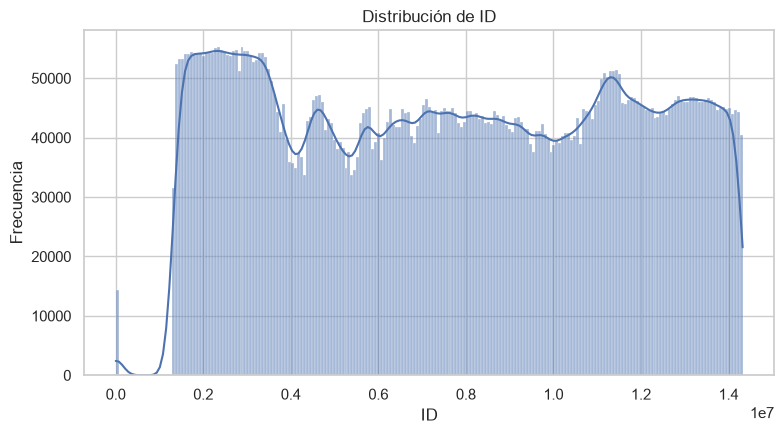

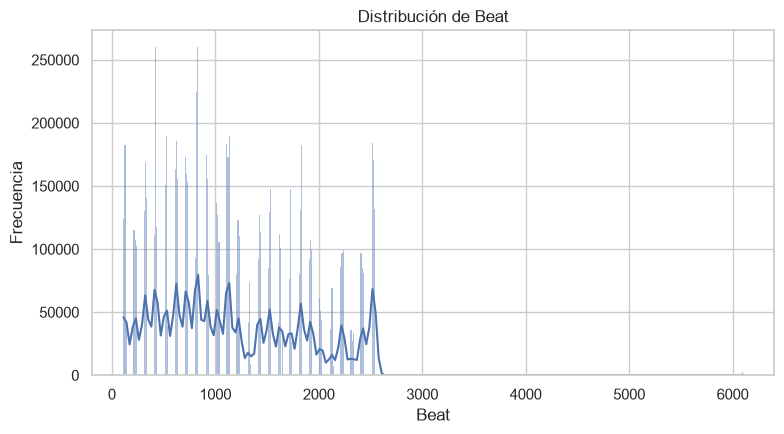

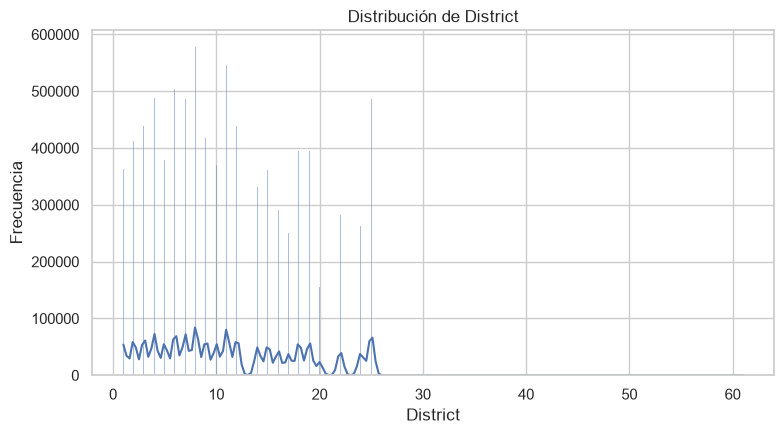

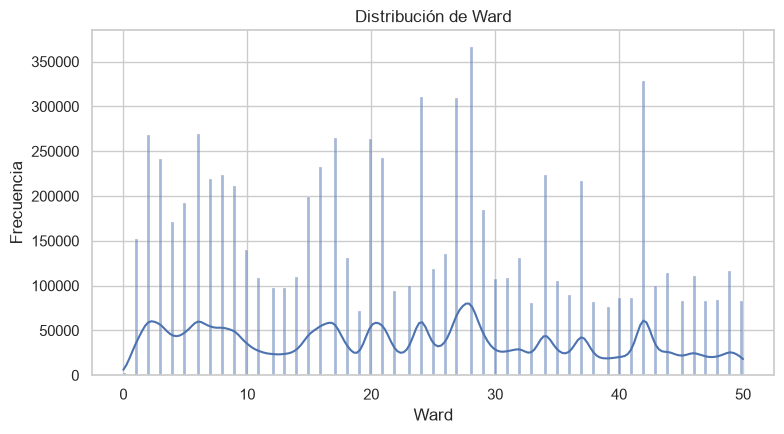

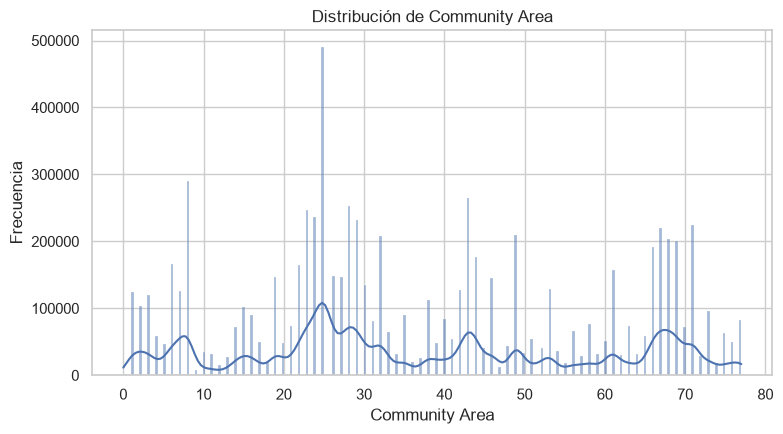

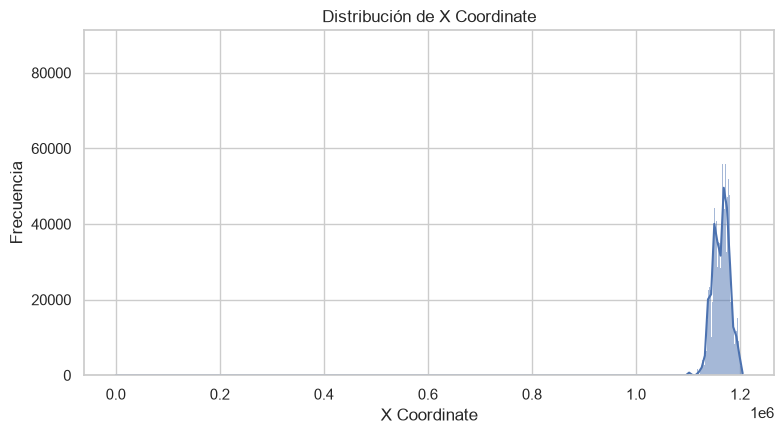

In [30]:
# ============================================================
# 6.1 HISTOGRAMAS NUMÉRICOS — TOP 6
# ============================================================
for c in numeric_cols[:6]:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.histplot(df_clean[c].dropna(), kde=True, ax=ax)
    ax.set_title(f"Distribución de {c}")
    ax.set_xlabel(c)
    ax.set_ylabel("Frecuencia")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"hist_{c}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


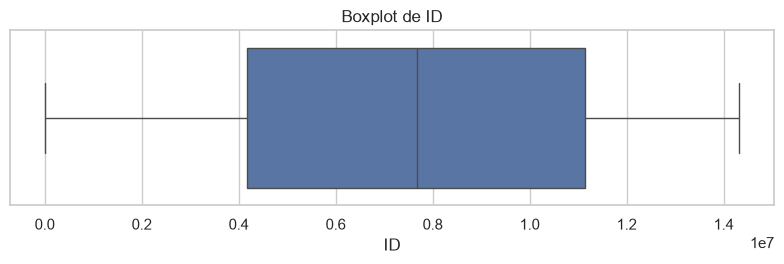

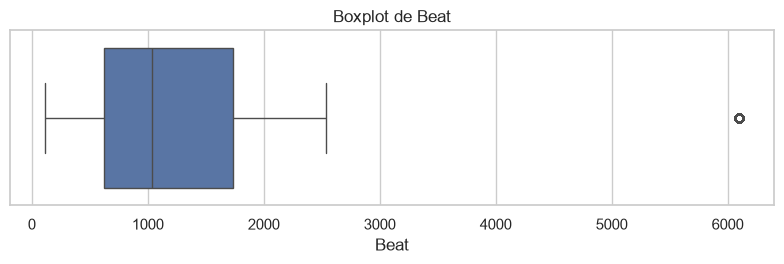

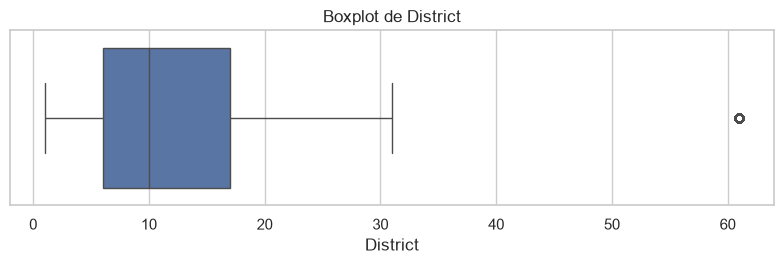

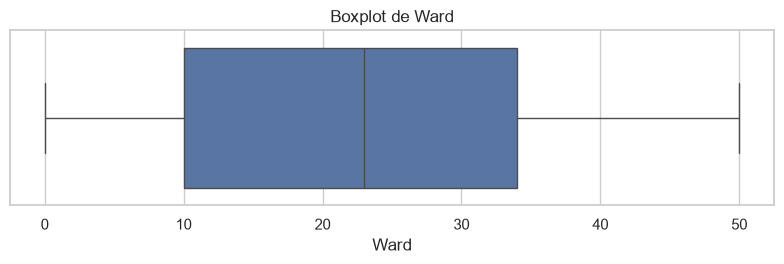

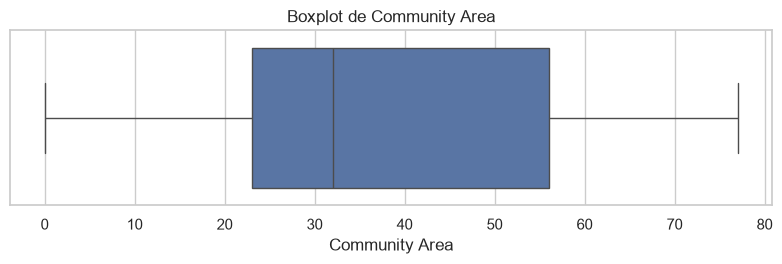

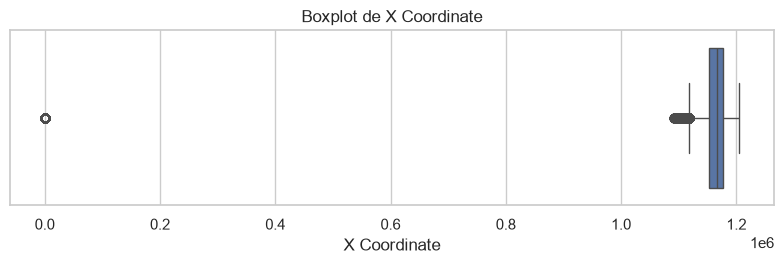

In [31]:
# ============================================================
# 6.2 BOXPLOTS NUMÉRICOS — TOP 6
# ============================================================
for c in numeric_cols[:6]:
    fig, ax = plt.subplots(figsize=(8, 2.8))
    sns.boxplot(x=df_clean[c], ax=ax)
    ax.set_title(f"Boxplot de {c}")
    ax.set_xlabel(c)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"box_{c}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


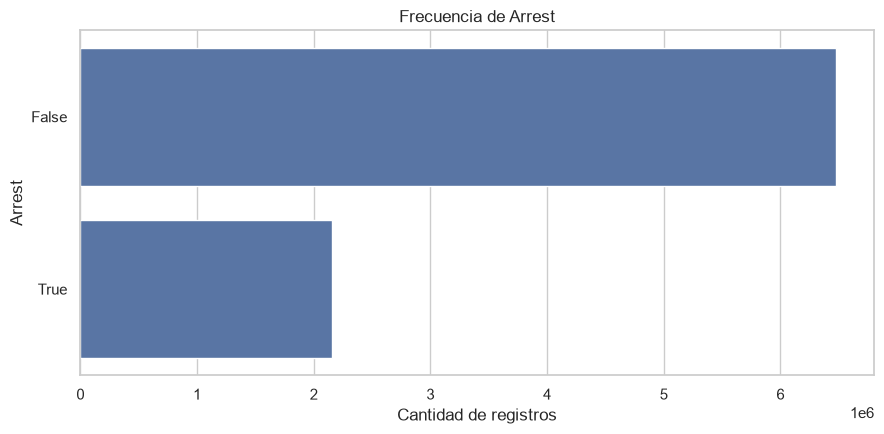

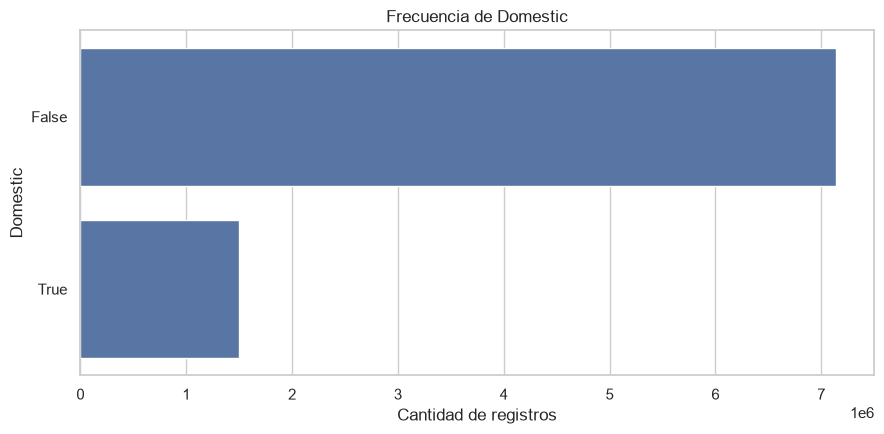

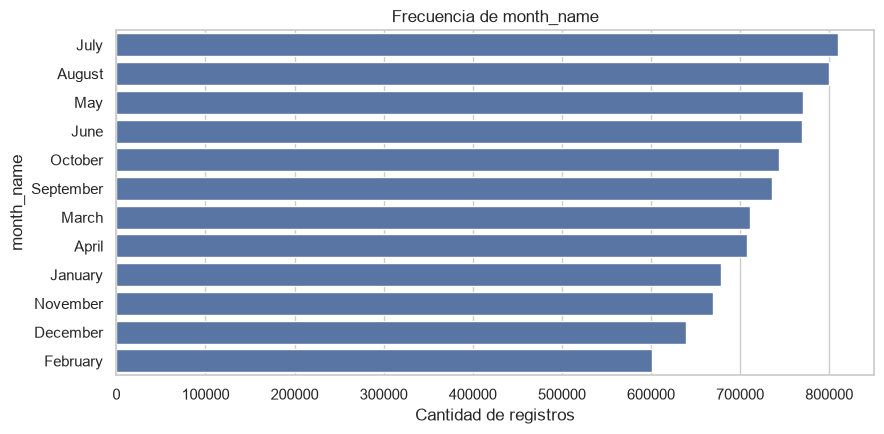

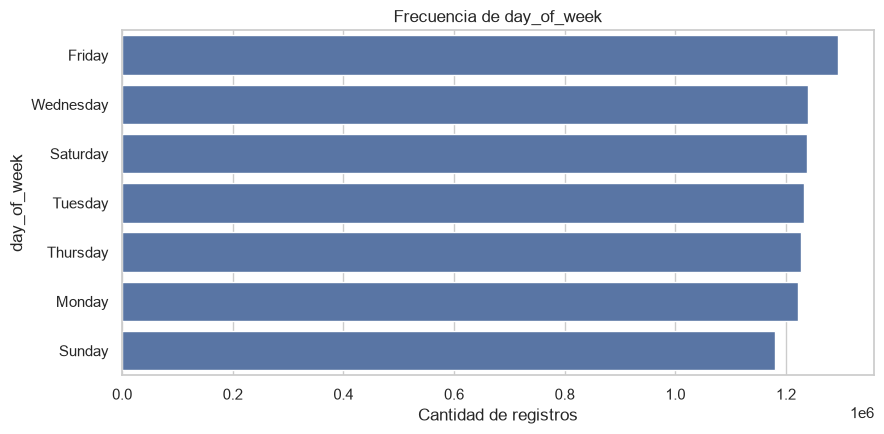

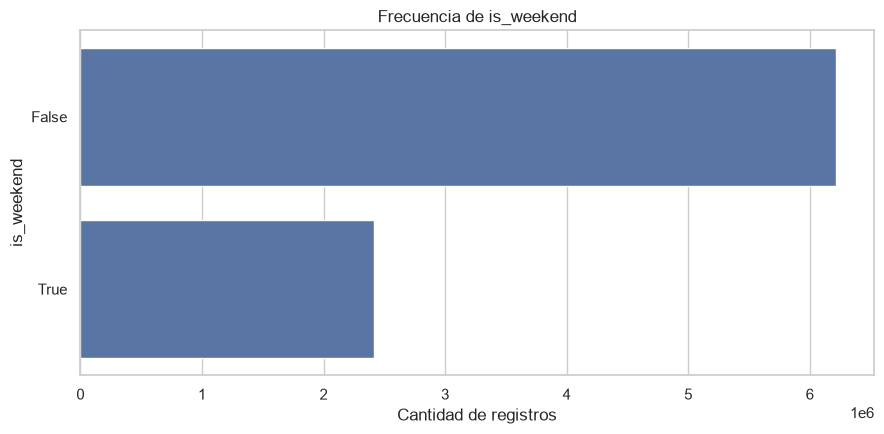

In [32]:
# ============================================================
# 6.3 BARRAS: CATEGÓRICAS DE MENOR CARDINALIDAD
# ============================================================
low_card = [c for c in categorical_cols if 2 <= df_clean[c].nunique(dropna=True) <= 20]

for c in low_card[:6]:
    counts = df_clean[c].value_counts(dropna=False).head(15)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.barplot(x=counts.values, y=counts.index.astype(str), ax=ax)
    ax.set_title(f"Frecuencia de {c}")
    ax.set_xlabel("Cantidad de registros")
    ax.set_ylabel(c)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"bar_{c}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# 7. Relación entre atributos

La rúbrica pide Pearson/Spearman y relaciones interesantes. Se calculan ambas cuando hay suficiente variación numérica.


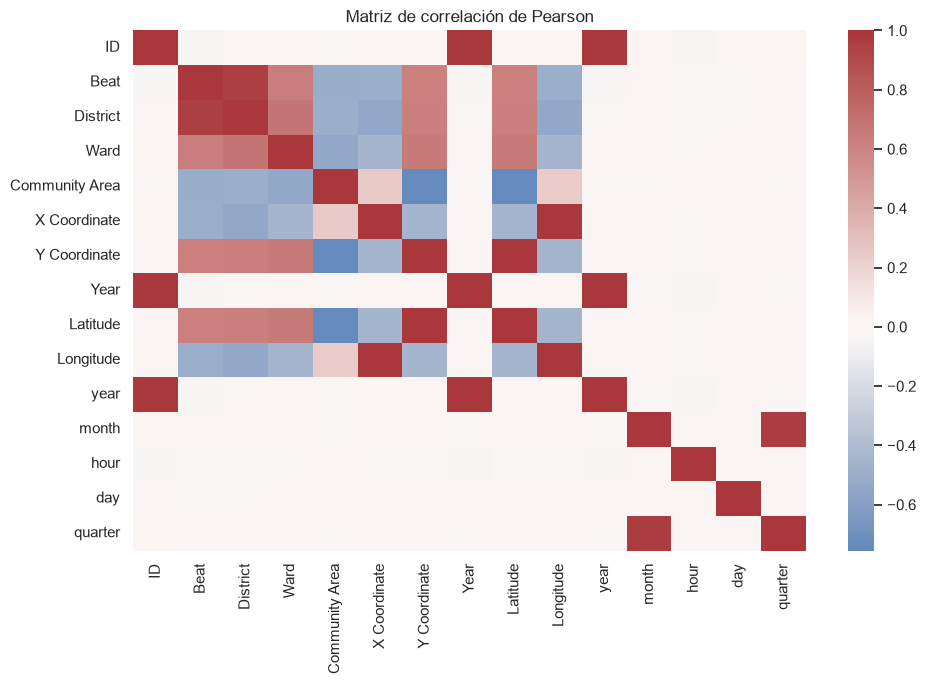

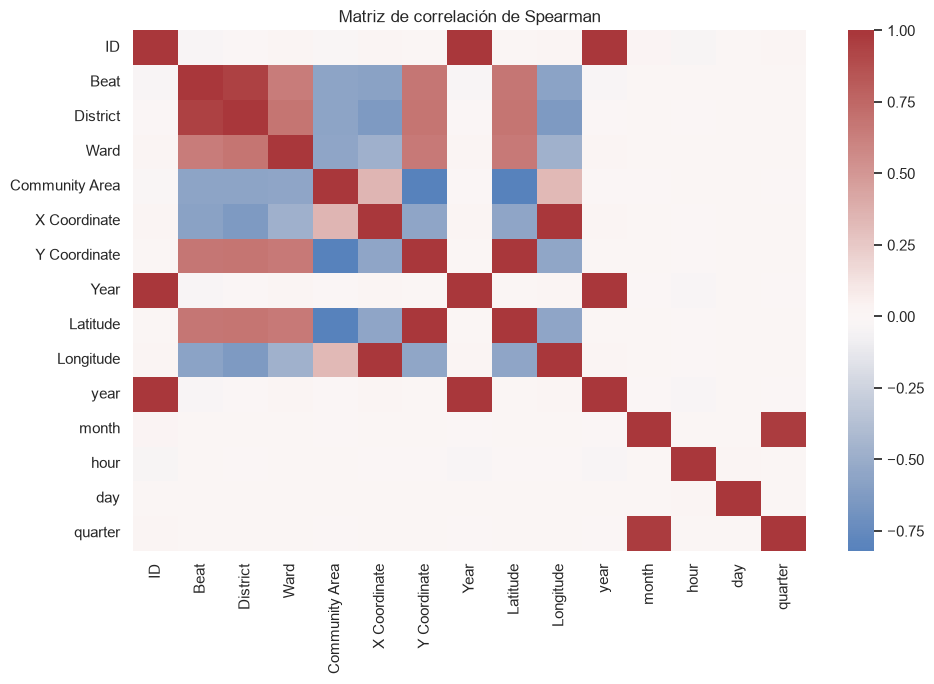

,atributo_1,atributo_2,pearson,abs_pearson
157,year,Year,1.000000,1.000000
126,Latitude,Y Coordinate,0.999994,0.999994
140,Longitude,X Coordinate,0.999818,0.999818
105,Year,ID,0.983223,0.983223
150,year,ID,0.983223,0.983223
221,quarter,month,0.969501,0.969501
31,District,Beat,0.952409,0.952409
94,Y Coordinate,Community Area,-0.755183,0.755183
124,Latitude,Community Area,-0.754257,0.754257
47,Ward,District,0.673057,0.673057


In [33]:
# ============================================================
# 7.1 CORRELACIONES PEARSON Y SPEARMAN
# ============================================================
if len(numeric_cols) >= 2:
    pearson = df_clean[numeric_cols].corr(method="pearson")
    spearman = df_clean[numeric_cols].corr(method="spearman")

    fig, ax = plt.subplots(figsize=(10, 7))
    sns.heatmap(pearson, cmap="vlag", center=0, annot=False, ax=ax)
    ax.set_title("Matriz de correlación de Pearson")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "correlacion_pearson.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(10, 7))
    sns.heatmap(spearman, cmap="vlag", center=0, annot=False, ax=ax)
    ax.set_title("Matriz de correlación de Spearman")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "correlacion_spearman.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Pares más relacionados, sin diagonal
    mask = np.triu(np.ones_like(pearson, dtype=bool))
    pairs = pearson.mask(mask).stack().reset_index()
    pairs.columns = ["atributo_1", "atributo_2", "pearson"]
    pairs["abs_pearson"] = pairs["pearson"].abs()
    display(pairs.sort_values("abs_pearson", ascending=False).head(15))
else:
    print("Se requieren al menos dos variables numéricas.")


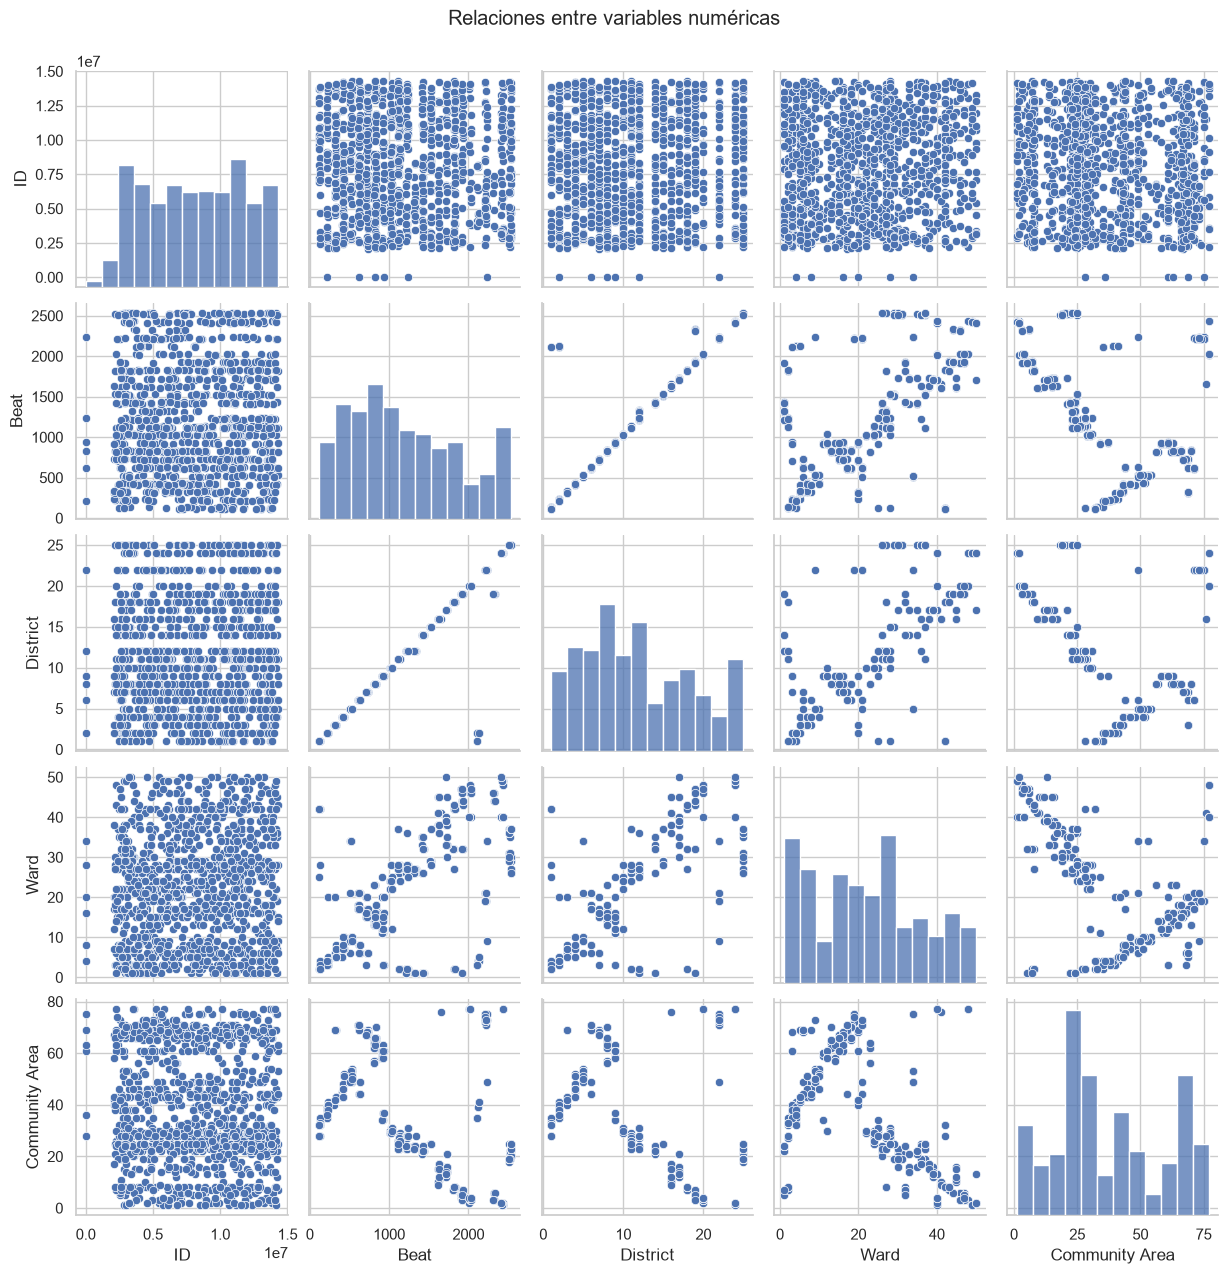

In [34]:
# ============================================================
# 7.2 PAIRPLOT — SOLO SI EL DATASET ES MANEJABLE
# ============================================================
if len(numeric_cols) >= 2:
    pair_cols = numeric_cols[:5]
    sample_n = min(1200, len(df_clean))
    sample = df_clean[pair_cols].sample(sample_n, random_state=RANDOM_STATE).dropna()
    if len(sample) > 20:
        g = sns.pairplot(sample)
        g.fig.suptitle("Relaciones entre variables numéricas", y=1.02)
        g.savefig(FIG_DIR / "pairplot_numericas.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close(g.fig)


# 8. Variables de tiempo y espacio

El paper centra parte de su propuesta en **patrones espaciales y temporales**, incluyendo cambios por mes, día de la semana y periodos del día. fileciteturn0file0L314-L339

Esta sección crea agregaciones que luego pueden alimentar las hipótesis y el proyecto de Visual Analytics.


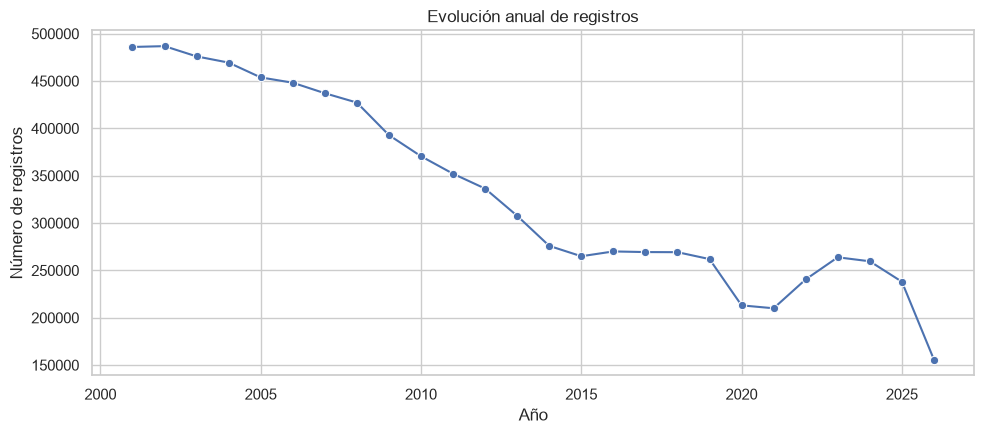

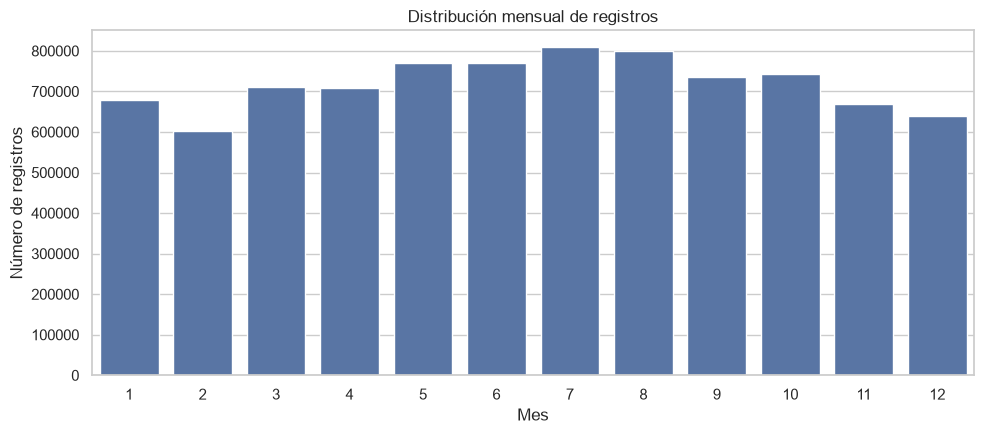

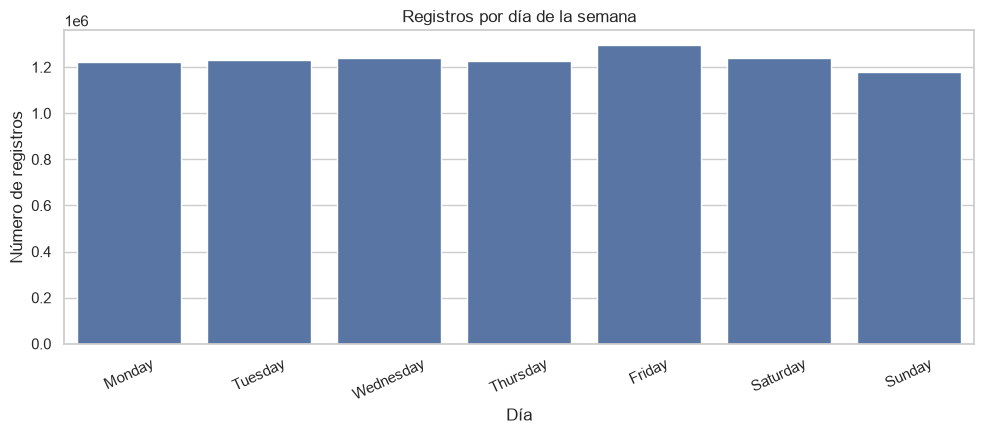

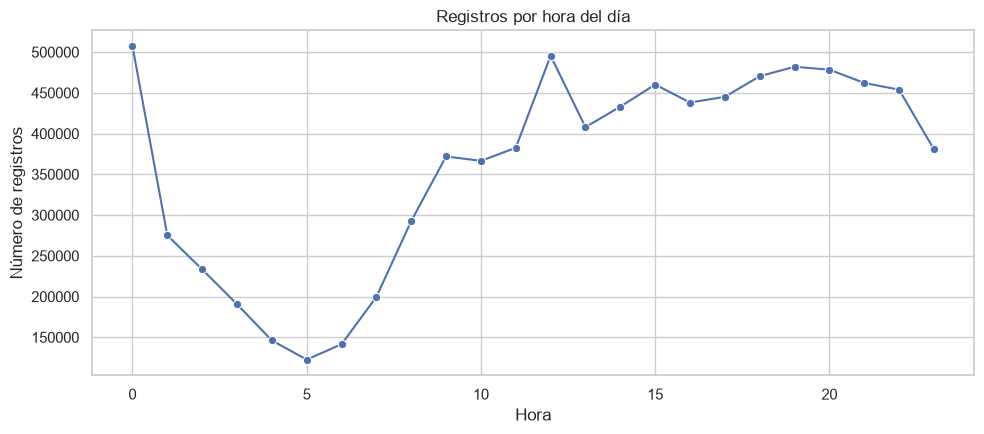

In [35]:
# ============================================================
# 8.1 EVOLUCIÓN TEMPORAL
# ============================================================
if "year" in df_clean.columns:
    yearly = df_clean.groupby("year").size().rename("n_crimes").reset_index()

    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.lineplot(data=yearly, x="year", y="n_crimes", marker="o", ax=ax)
    ax.set_title("Evolución anual de registros")
    ax.set_xlabel("Año")
    ax.set_ylabel("Número de registros")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "temporal_anual.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

if "month" in df_clean.columns:
    monthly = df_clean.groupby("month").size().rename("n_crimes").reset_index()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.barplot(data=monthly, x="month", y="n_crimes", ax=ax)
    ax.set_title("Distribución mensual de registros")
    ax.set_xlabel("Mes")
    ax.set_ylabel("Número de registros")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "temporal_mensual.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

if "day_of_week" in df_clean.columns:
    order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
    d = df_clean["day_of_week"].value_counts().reindex(order).dropna().reset_index()
    d.columns = ["day_of_week", "n_crimes"]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.barplot(data=d, x="day_of_week", y="n_crimes", ax=ax)
    ax.set_title("Registros por día de la semana")
    ax.set_xlabel("Día")
    ax.set_ylabel("Número de registros")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "temporal_dia_semana.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

if "hour" in df_clean.columns:
    h = df_clean.groupby("hour").size().rename("n_crimes").reset_index()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.lineplot(data=h, x="hour", y="n_crimes", marker="o", ax=ax)
    ax.set_title("Registros por hora del día")
    ax.set_xlabel("Hora")
    ax.set_ylabel("Número de registros")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "temporal_hora.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# 9. Hipótesis / preguntas de investigación

Propongo tres preguntas alineadas con el paper, pero deben ajustarse a **las variables que realmente tenga tu dataset**.

**H1 — Espacio:** ¿La distribución y/o el tipo de delito cambia significativamente entre diferentes unidades o regiones espaciales?

**H2 — Tiempo:** ¿Existen patrones temporales (año, mes, día de semana u hora) asociados a cambios en la frecuencia o composición de los delitos?

**H3 — Hotspots / concentración:** ¿Los delitos se concentran de manera no uniforme en el territorio, de modo que algunas zonas presentan recurrencia o intensidad desproporcionada?

Estas preguntas reflejan las tareas T2–T5 del artículo: patrones por región, evolución temporal, hotspots y cambios de patrones a través del tiempo. fileciteturn0file0L306-L339

> **Importante:** la evidencia final debe decir “apoya”, “no apoya” o “evidencia insuficiente”, evitando afirmar causalidad cuando el dataset solo permite asociaciones descriptivas.


In [36]:
# ============================================================
# 9. CONFIGURACIÓN DE HIPÓTESIS
# ============================================================

HYPOTHESES = {
    "H1": {
        "pregunta": "¿La distribución y/o el tipo de delito cambia entre diferentes unidades o regiones espaciales?",
        "variables": [SITE_COL, CRIME_COL],
    },
    "H2": {
        "pregunta": "¿Existen patrones temporales asociados a cambios en la frecuencia o composición de los delitos?",
        "variables": [DATE_COL, CRIME_COL],
    },
    "H3": {
        "pregunta": "¿Los delitos se concentran de manera no uniforme en el territorio, generando zonas de alta recurrencia o intensidad?",
        "variables": [SITE_COL],
    }
}

for k, v in HYPOTHESES.items():
    print(k, "→", v["pregunta"])


H1 → ¿La distribución y/o el tipo de delito cambia entre diferentes unidades o regiones espaciales?
H2 → ¿Existen patrones temporales asociados a cambios en la frecuencia o composición de los delitos?
H3 → ¿Los delitos se concentran de manera no uniforme en el territorio, generando zonas de alta recurrencia o intensidad?


## 9.1 H1 — Diferencias por espacio

Cuando existe una variable de sitio/zona y un tipo de delito, un primer análisis útil es:
1. frecuencia por zona;
2. composición de delitos por zona;
3. top zonas;
4. contraste estadístico si corresponde.

La idea es evitar que los delitos más frecuentes “oculten” otros patrones locales, una preocupación explícita del paper. fileciteturn0file0L229-L264


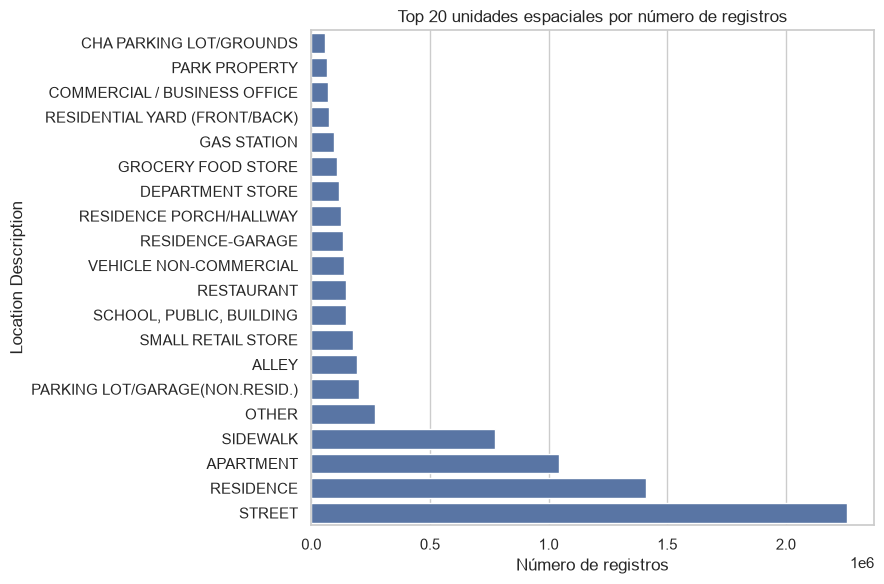

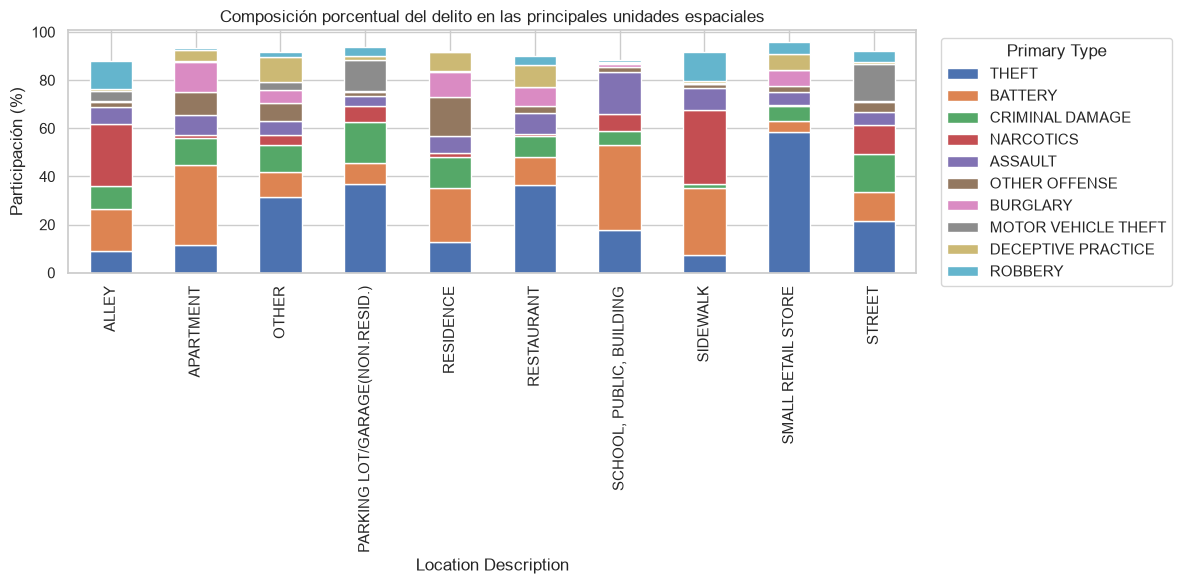

Chi-cuadrado de independencia: chi2=10030007.901, p=0, gl=7161
Interpretación orientativa: p < 0.05 sugiere asociación entre las variables, no causalidad.


In [37]:
# ============================================================
# H1 — ESPACIO
# ============================================================
if SITE_COL is not None and SITE_COL in df_clean.columns:
    site_counts = df_clean[SITE_COL].value_counts().head(20).sort_values()

    fig, ax = plt.subplots(figsize=(9, 6))
    sns.barplot(x=site_counts.values, y=site_counts.index.astype(str), ax=ax)
    ax.set_title("Top 20 unidades espaciales por número de registros")
    ax.set_xlabel("Número de registros")
    ax.set_ylabel(SITE_COL)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "H1_top_espacios.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    if CRIME_COL is not None and CRIME_COL in df_clean.columns:
        top_sites = df_clean[SITE_COL].value_counts().head(10).index
        comp = (df_clean[df_clean[SITE_COL].isin(top_sites)]
                .groupby([SITE_COL, CRIME_COL]).size()
                .reset_index(name="n"))
        comp["share"] = comp.groupby(SITE_COL)["n"].transform(lambda x: 100*x/x.sum())

        pivot = comp.pivot(index=SITE_COL, columns=CRIME_COL, values="share").fillna(0)
        # Mostrar solo los tipos más frecuentes globalmente
        top_crimes = df_clean[CRIME_COL].value_counts().head(10).index
        pivot = pivot.reindex(columns=[c for c in top_crimes if c in pivot.columns], fill_value=0)

        fig, ax = plt.subplots(figsize=(12, 6))
        pivot.plot(kind="bar", stacked=True, ax=ax)
        ax.set_title("Composición porcentual del delito en las principales unidades espaciales")
        ax.set_xlabel(SITE_COL)
        ax.set_ylabel("Participación (%)")
        ax.legend(title=CRIME_COL, bbox_to_anchor=(1.02, 1), loc="upper left")
        fig.tight_layout()
        fig.savefig(FIG_DIR / "H1_composicion_espacial.png", dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        # Chi-cuadrado: asociación entre zona y tipo de delito
        contingency = pd.crosstab(df_clean[SITE_COL], df_clean[CRIME_COL])
        if contingency.shape[0] >= 2 and contingency.shape[1] >= 2:
            chi2, p, dof, expected = stats.chi2_contingency(contingency)
            print(f"Chi-cuadrado de independencia: chi2={chi2:.3f}, p={p:.6g}, gl={dof}")
            print("Interpretación orientativa: p < 0.05 sugiere asociación entre las variables, no causalidad.")
else:
    print("H1 requiere configurar SITE_COL.")


### Plantilla de conclusión H1 para el informe

Completa después de revisar los resultados:

> **Conclusión H1:** La evidencia [apoya / no apoya / no permite concluir] que los patrones de delito difieren entre unidades espaciales. Esto se observa en [gráfico/tabla], donde [hallazgo concreto]. El resultado es relevante para Visual Analytics porque [permite priorizar comparación local / detectar concentración / explorar sitios específicos].


## 9.2 H2 — Evolución temporal

El paper señala explícitamente el interés por saber si los patrones cambian a lo largo de los años y si existen comportamientos estacionales. fileciteturn0file0L299-L322


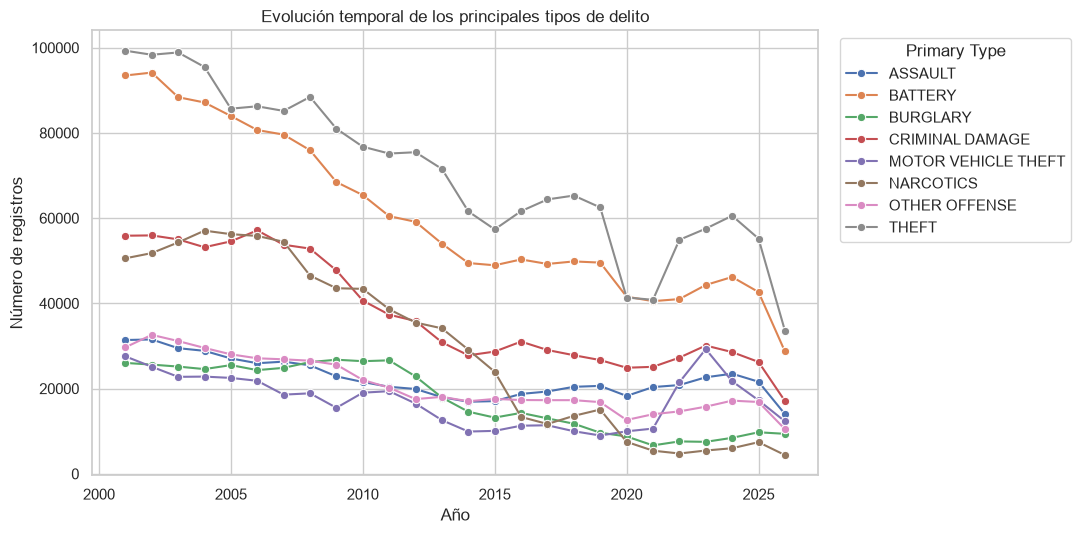

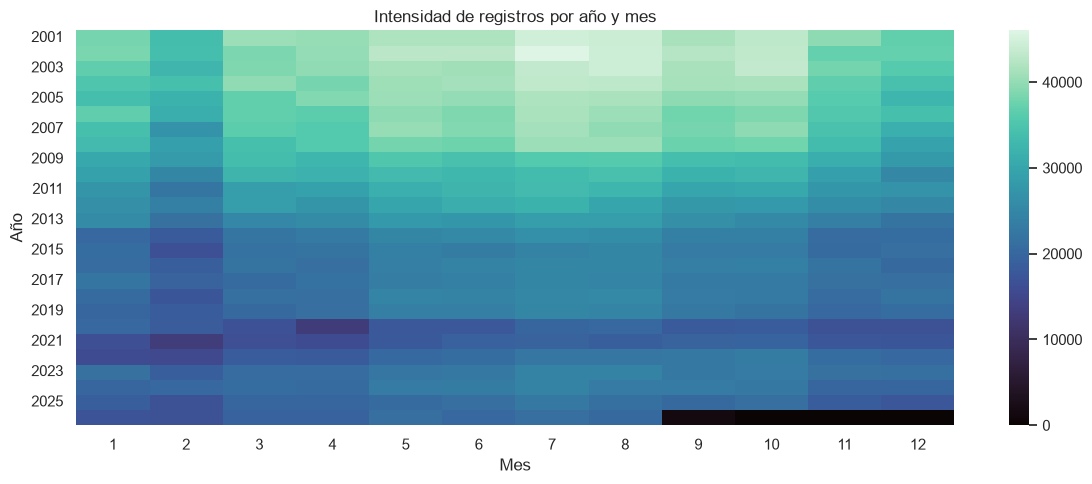

In [38]:
# ============================================================
# H2 — TIEMPO
# ============================================================
if "year" in df_clean.columns:
    if CRIME_COL is not None and CRIME_COL in df_clean.columns:
        top_crimes = df_clean[CRIME_COL].value_counts().head(8).index
        tmp = (df_clean[df_clean[CRIME_COL].isin(top_crimes)]
               .groupby(["year", CRIME_COL]).size().reset_index(name="n"))

        fig, ax = plt.subplots(figsize=(11, 5.5))
        sns.lineplot(data=tmp, x="year", y="n", hue=CRIME_COL, marker="o", ax=ax)
        ax.set_title("Evolución temporal de los principales tipos de delito")
        ax.set_xlabel("Año")
        ax.set_ylabel("Número de registros")
        ax.legend(title=CRIME_COL, bbox_to_anchor=(1.02, 1), loc="upper left")
        fig.tight_layout()
        fig.savefig(FIG_DIR / "H2_evolucion_crime.png", dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)

    # Heatmap año x mes si hay month
    if "month" in df_clean.columns:
        heat = pd.crosstab(df_clean["year"], df_clean["month"])
        fig, ax = plt.subplots(figsize=(12, 5))
        sns.heatmap(heat, cmap="mako", annot=False, ax=ax)
        ax.set_title("Intensidad de registros por año y mes")
        ax.set_xlabel("Mes")
        ax.set_ylabel("Año")
        fig.tight_layout()
        fig.savefig(FIG_DIR / "H2_heatmap_anio_mes.png", dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)
else:
    print("H2 requiere DATE_COL para generar variables temporales.")


### Plantilla de conclusión H2

> **Conclusión H2:** Los resultados muestran [tendencia/estacionalidad/cambio de composición] en [periodo]. La evidencia principal es [gráfico], donde se observa [hallazgo]. Esto sugiere que la futura Visual Analytics debería permitir filtrar por [año/mes/día/hora] y comparar periodos.


## 9.3 H3 — Concentración y hotspots

El paper define hotspot de forma más amplia que “lugares con más delitos”: también considera sitios donde los delitos son frecuentes aunque su magnitud sea menor, o donde aparecen picos intensos en periodos concretos. fileciteturn0file0L448-L462

A continuación se crea una primera aproximación **EDA**, no una reproducción exacta del algoritmo de CrimAnalyzer.


Percentil 90: 44050.10
Percentil 95: 135102.15


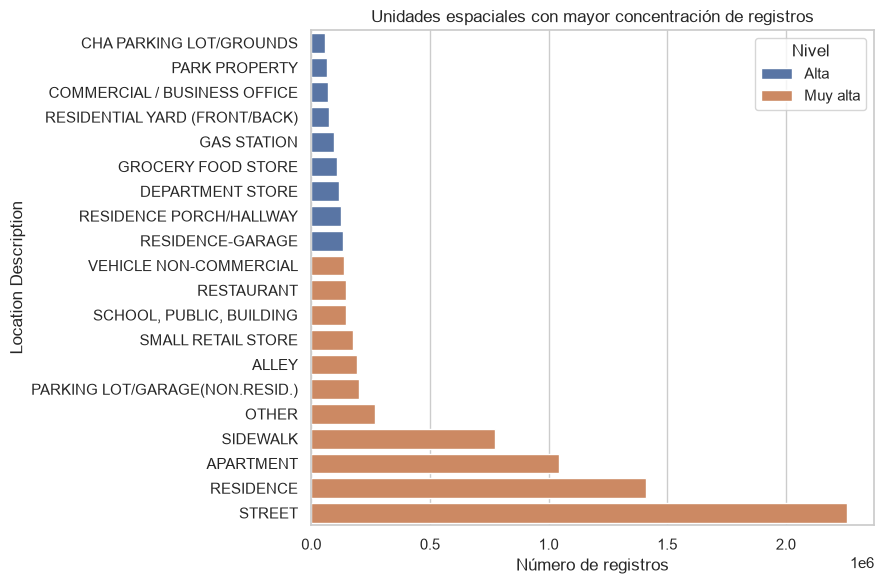

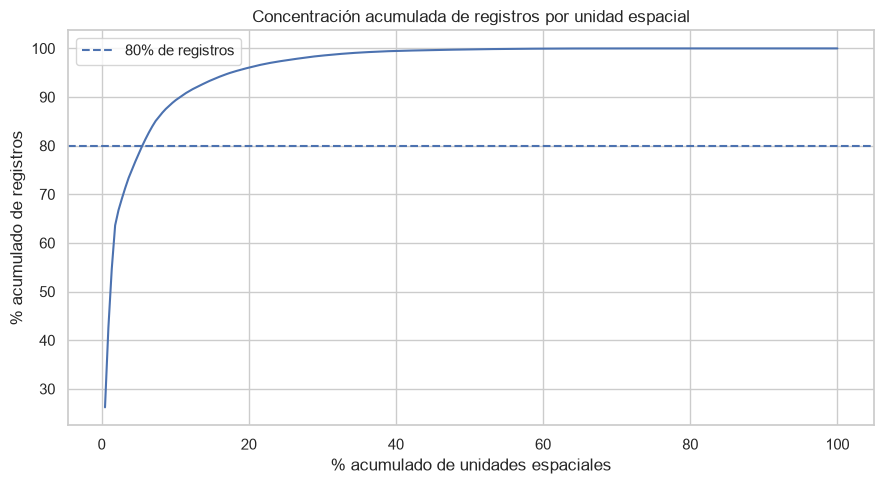

,Location Description,n_crimes,nivel_concentracion
190,STREET,2258752,Muy alta
161,RESIDENCE,1409285,Muy alta
17,APARTMENT,1043148,Muy alta
185,SIDEWALK,772580,Muy alta
141,OTHER,269964,Muy alta
149,PARKING LOT/GARAGE(NON.RESID.),202912,Muy alta
15,ALLEY,191860,Muy alta
186,SMALL RETAIL STORE,176573,Muy alta
182,"SCHOOL, PUBLIC, BUILDING",146365,Muy alta
168,RESTAURANT,146112,Muy alta


In [39]:
# ============================================================
# H3 — CONCENTRACIÓN ESPACIAL
# ============================================================
if SITE_COL is not None and SITE_COL in df_clean.columns:
    site = df_clean.groupby(SITE_COL).size().rename("n_crimes").reset_index()
    q90 = site["n_crimes"].quantile(0.90)
    q95 = site["n_crimes"].quantile(0.95)

    site["nivel_concentracion"] = np.select(
        [site["n_crimes"] >= q95, site["n_crimes"] >= q90],
        ["Muy alta", "Alta"],
        default="Media/baja"
    )

    print(f"Percentil 90: {q90:.2f}")
    print(f"Percentil 95: {q95:.2f}")

    top = site.sort_values("n_crimes", ascending=False).head(20).sort_values("n_crimes")

    fig, ax = plt.subplots(figsize=(9, 6))
    sns.barplot(data=top, x="n_crimes", y=SITE_COL, hue="nivel_concentracion", dodge=False, ax=ax)
    ax.set_title("Unidades espaciales con mayor concentración de registros")
    ax.set_xlabel("Número de registros")
    ax.set_ylabel(SITE_COL)
    ax.legend(title="Nivel")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "H3_concentracion_espacial.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Curva acumulada tipo Pareto
    pareto = site.sort_values("n_crimes", ascending=False).reset_index(drop=True)
    pareto["cum_pct_crimes"] = 100*pareto["n_crimes"].cumsum()/pareto["n_crimes"].sum()
    pareto["cum_pct_sites"] = 100*(pareto.index+1)/len(pareto)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(pareto["cum_pct_sites"], pareto["cum_pct_crimes"])
    ax.axhline(80, linestyle="--", label="80% de registros")
    ax.set_title("Concentración acumulada de registros por unidad espacial")
    ax.set_xlabel("% acumulado de unidades espaciales")
    ax.set_ylabel("% acumulado de registros")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / "H3_pareto_concentracion.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    display(site.sort_values("n_crimes", ascending=False).head(20))
else:
    print("H3 requiere SITE_COL.")


### 9.3.1 Hotspots temporales con NMF (opcional)

El paper usa NMF para descomponer una matriz donde las filas son sitios y las columnas son intervalos temporales; las columnas de `W` representan hotspots y las filas de `H` su intensidad/ocurrencia temporal. fileciteturn0file0L567-L626

Esta implementación es una **aproximación educativa** para explorar la idea. No afirma reproducir exactamente el CrimAnalyzer original, que utiliza una versión dispersa de NMF y binarización de `H`.


Error de reconstrucción NMF (MSE): 4591.989595945399


,Hotspot_1,Hotspot_2,Hotspot_3
Location Description,,,
ABANDONED BUILDING,0.701533,0.073299,0.000000
AIRCRAFT,0.000000,0.027446,0.000000
AIRPORT BUILDING NON-TERMINAL - NON-SECURE AREA,0.000000,0.043013,0.000000
AIRPORT BUILDING NON-TERMINAL - SECURE AREA,0.000000,0.024927,0.000000
AIRPORT EXTERIOR - NON-SECURE AREA,0.000000,0.037262,0.000000
AIRPORT EXTERIOR - SECURE AREA,0.000000,0.018846,0.000000
AIRPORT PARKING LOT,0.000000,0.059005,0.000000
AIRPORT TERMINAL LOWER LEVEL - NON-SECURE AREA,0.000000,0.074420,0.000000
AIRPORT TERMINAL LOWER LEVEL - SECURE AREA,0.000000,0.033727,0.000000


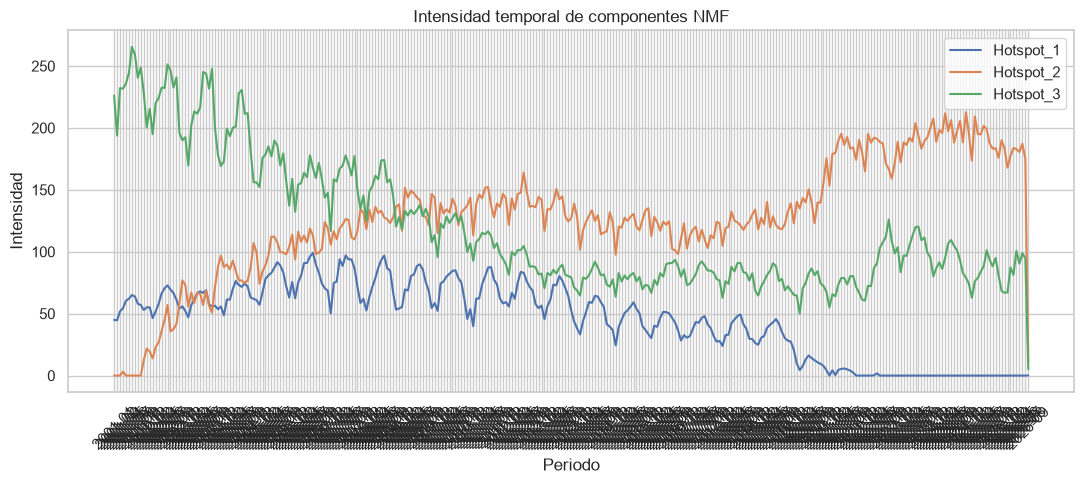


Hotspot_1 — sitios con mayor peso


Location Description
SIDEWALK                          38.310280
RESIDENCE                         23.704959
STREET                            14.973647
OTHER                             12.287417
PARKING LOT/GARAGE(NON.RESID.)     9.531660
RESIDENCE-GARAGE                   7.151905
RESIDENCE PORCH/HALLWAY            6.397342
SCHOOL, PUBLIC, BUILDING           5.520616
VEHICLE NON-COMMERCIAL             4.511715
RESIDENTIAL YARD (FRONT/BACK)      4.054684
Name: Hotspot_1, dtype: float64


Hotspot_2 — sitios con mayor peso


Location Description
APARTMENT                                 16.784253
STREET                                     4.088361
SIDEWALK                                   3.481279
RESIDENCE                                  2.779425
SMALL RETAIL STORE                         2.337865
PARKING LOT / GARAGE (NON RESIDENTIAL)     1.726013
RESTAURANT                                 1.557399
DEPARTMENT STORE                           1.240793
VEHICLE NON-COMMERCIAL                     1.132991
OTHER (SPECIFY)                            0.879599
Name: Hotspot_2, dtype: float64


Hotspot_3 — sitios con mayor peso


Location Description
STREET                            51.218029
RESIDENCE                         25.826233
APARTMENT                          9.580663
ALLEY                              3.146094
SIDEWALK                           3.008350
OTHER                              2.978205
GROCERY FOOD STORE                 2.589460
SMALL RETAIL STORE                 2.269724
PARKING LOT/GARAGE(NON.RESID.)     2.132043
SCHOOL, PUBLIC, BUILDING           2.112332
Name: Hotspot_3, dtype: float64

In [40]:
# ============================================================
# H3.2 — NMF EXPLORATORIO
# ============================================================
def nmf_hotspots_eda(data, site_col, time_col="month_period", n_components=3,
                      min_site_records=5, random_state=42):
    tmp = data.dropna(subset=[site_col, time_col]).copy()

    # Conservar sitios con suficiente presencia
    site_freq = tmp[site_col].value_counts()
    valid_sites = site_freq[site_freq >= min_site_records].index
    tmp = tmp[tmp[site_col].isin(valid_sites)]

    X = pd.crosstab(tmp[site_col], tmp[time_col])

    if X.shape[0] < n_components or X.shape[1] < n_components:
        raise ValueError("No hay suficientes sitios/periodos para ejecutar NMF con este rango.")

    model = NMF(
        n_components=n_components,
        init="nndsvda",
        random_state=random_state,
        max_iter=800
    )
    W = model.fit_transform(X.values)
    H = model.components_

    W_df = pd.DataFrame(W, index=X.index, columns=[f"Hotspot_{i+1}" for i in range(n_components)])
    H_df = pd.DataFrame(H, columns=X.columns, index=[f"Hotspot_{i+1}" for i in range(n_components)])

    return X, model, W_df, H_df

if DATE_COL is not None and SITE_COL is not None and DATE_COL+"_parsed" in df_clean.columns:
    nmf_df = df_clean.copy()
    nmf_df["month_period"] = nmf_df[DATE_COL+"_parsed"].dt.to_period("M").astype(str)

    try:
        X_nmf, nmf_model, W_nmf, H_nmf = nmf_hotspots_eda(
            nmf_df, SITE_COL, n_components=3, min_site_records=5,
            random_state=RANDOM_STATE
        )

        print("Error de reconstrucción NMF (MSE):",
              mean_squared_error(X_nmf.values, np.dot(W_nmf.values, H_nmf.values)))

        display(W_nmf.head(15))

        fig, ax = plt.subplots(figsize=(11, 5))
        for h in H_nmf.index:
            ax.plot(H_nmf.columns, H_nmf.loc[h], label=h)
        ax.set_title("Intensidad temporal de componentes NMF")
        ax.set_xlabel("Periodo")
        ax.set_ylabel("Intensidad")
        ax.tick_params(axis="x", rotation=45)
        ax.legend()
        fig.tight_layout()
        fig.savefig(FIG_DIR / "H3_NMF_temporal.png", dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        # Sitios principales por hotspot
        for h in W_nmf.columns:
            print(f"\n{h} — sitios con mayor peso")
            display(W_nmf[h].sort_values(ascending=False).head(10))
    except Exception as e:
        print("NMF no ejecutado:", e)
else:
    print("NMF requiere DATE_COL y SITE_COL correctamente configuradas.")


# 10. Dashboard EDA compacto

La rúbrica solicita un pequeño dashboard organizado. Esta vista resume tamaño, faltantes, top categorías y evolución temporal, siempre que las variables necesarias estén disponibles.


KeyError: 'null_pct'

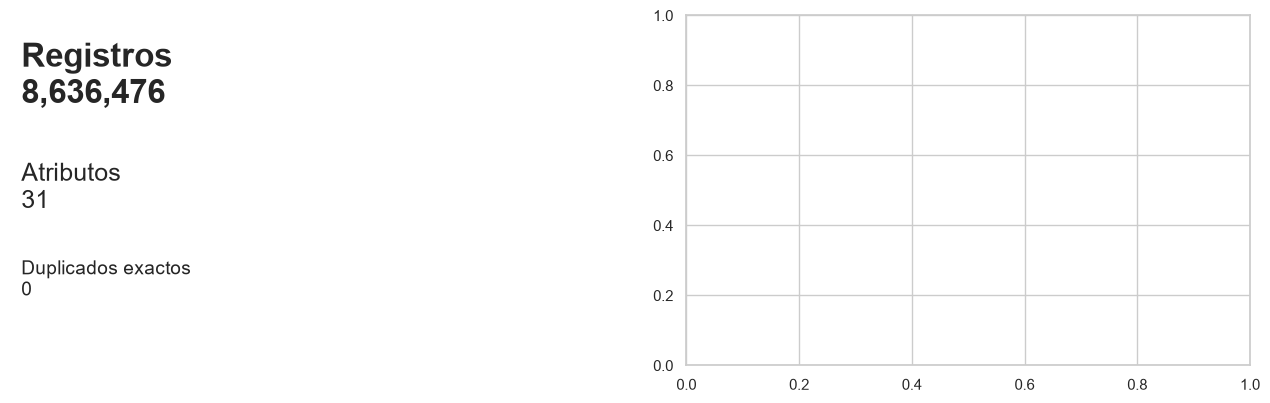

In [41]:
# ============================================================
# 10. DASHBOARD
# ============================================================

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2)

# Panel 1: registros
ax1 = fig.add_subplot(gs[0, 0])
ax1.axis("off")
ax1.text(0.02, 0.75, f"Registros\n{len(df_clean):,}", fontsize=24, fontweight="bold")
ax1.text(0.02, 0.45, f"Atributos\n{df_clean.shape[1]:,}", fontsize=18)
ax1.text(0.02, 0.20, f"Duplicados exactos\n{df_clean.duplicated().sum():,}", fontsize=14)

# Panel 2: faltantes
ax2 = fig.add_subplot(gs[0, 1])
miss_plot = missing.head(10).sort_values("null_pct")
sns.barplot(data=miss_plot, x="null_pct", y="atributo", ax=ax2)
ax2.set_title("Top atributos con faltantes")
ax2.set_xlabel("% nulos")
ax2.set_ylabel("")

# Panel 3: categorías
ax3 = fig.add_subplot(gs[1, 0])
if CRIME_COL is not None and CRIME_COL in df_clean.columns:
    vc = df_clean[CRIME_COL].value_counts().head(10).sort_values()
    sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax3)
    ax3.set_title(f"Top 10 categorías de {CRIME_COL}")
    ax3.set_xlabel("Registros")
    ax3.set_ylabel("")
else:
    ax3.text(0.1, 0.5, "Configura CRIME_COL", fontsize=14)
    ax3.axis("off")

# Panel 4: temporal
ax4 = fig.add_subplot(gs[1, 1])
if "year" in df_clean.columns:
    yr = df_clean.groupby("year").size().reset_index(name="n")
    sns.lineplot(data=yr, x="year", y="n", marker="o", ax=ax4)
    ax4.set_title("Evolución anual")
    ax4.set_xlabel("Año")
    ax4.set_ylabel("Registros")
else:
    ax4.text(0.1, 0.5, "Configura DATE_COL", fontsize=14)
    ax4.axis("off")

fig.suptitle("Dashboard exploratorio del dataset", fontsize=18, y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "dashboard_EDA.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


# 11. Resumen ejecutivo automático

Esta sección ayuda a redactar las partes de “Descripción”, “Problemas identificados” y “Conclusiones”. Los textos son **pistas basadas en resultados**, no una conclusión automática que debas copiar sin revisar.


In [ ]:
# ============================================================
# 11. RESUMEN DE HALLAZGOS
# ============================================================

def pct(x): return f"{100*x:.2f}%"

print("=== RESUMEN DEL DATASET ===")
print(f"- Registros: {len(df_clean):,}")
print(f"- Atributos: {df_clean.shape[1]}")
print(f"- Celdas nulas: {int(df_clean.isna().sum().sum()):,} "
      f"({pct(df_clean.isna().to_numpy().mean())})")
print(f"- Filas duplicadas exactas: {df_clean.duplicated().sum():,}")

if DATE_COL is not None and DATE_COL+"_parsed" in df_clean.columns:
    valid_dates = df_clean[DATE_COL+"_parsed"].dropna()
    if len(valid_dates):
        print(f"- Cobertura temporal: {valid_dates.min()} → {valid_dates.max()}")

if CRIME_COL is not None and CRIME_COL in df_clean.columns:
    print(f"- Tipos/categorías de {CRIME_COL}: {df_clean[CRIME_COL].nunique(dropna=True):,}")
    print("- Categorías principales:")
    display(df_clean[CRIME_COL].value_counts().head(10).to_frame("n"))

if SITE_COL is not None and SITE_COL in df_clean.columns:
    print(f"- Unidades espaciales de {SITE_COL}: {df_clean[SITE_COL].nunique(dropna=True):,}")
    print("- Unidades con más registros:")
    display(df_clean[SITE_COL].value_counts().head(10).to_frame("n"))


# 12. Matriz de trazabilidad para el informe

Usa esta tabla para demostrar que cada requisito de la rúbrica tiene una salida concreta del notebook.


In [ ]:
traceability = pd.DataFrame([
    ["Definición del problema", "Paper + planteamiento del proyecto", "Introducción / marco conceptual"],
    ["3 hipótesis", "H1, H2, H3", "Sección 9"],
    ["Plan de análisis", "Carga → wrangle → clean → explore", "Secciones 2–8"],
    ["Fuente de datos", "Metadatos/documentación del dataset", "Debe completarse según tu fuente real"],
    ["Formato original", "Extensión detectada por el notebook", "Sección 2"],
    ["Descripción de atributos", "attribute_table + estadísticas", "Sección 5"],
    ["Problemas de calidad", "missing + duplicados + dominio + outliers", "Sección 4"],
    ["Transformaciones", "df_clean + reglas documentadas", "Sección 4.7"],
    ["Respuesta a H1", "Gráficos + chi-cuadrado (si aplica)", "Sección 9.1"],
    ["Respuesta a H2", "Series temporales + heatmap", "Sección 9.2"],
    ["Respuesta a H3", "Concentración + Pareto + NMF opcional", "Sección 9.3"],
    ["Visual Analytics", "Necesidades de filtro espacial/temporal/tipo", "Sección 13"],
    ["Reproducibilidad", "Notebook + carpeta salidas_informe", "Anexo"]
], columns=["Requisito", "Evidencia", "Dónde encontrarla"])
display(traceability)
traceability.to_csv(TABLE_DIR / "08_trazabilidad_rubrica.csv", index=False)


# 13. Puente hacia la propuesta de Visual Analytics

El paper plantea que una solución útil debe permitir explorar regiones de interés y enlazar consultas espaciales, temporales y por tipo de crimen. También propone vistas vinculadas para patrones, evolución temporal y hotspots. fileciteturn0file0L439-L447 fileciteturn0file0L770-L900

A partir de tu EDA, completa estas prioridades:

**Prioridad 1 — Espacio:** [qué zonas/unidades deberían poder seleccionarse y compararse]

**Prioridad 2 — Tiempo:** [qué escalas: año, mes, día, hora]

**Prioridad 3 — Tipo de delito:** [qué categorías son relevantes y cuáles están dominadas por categorías muy frecuentes]

**Prioridad 4 — Hotspots:** [qué zonas recurrentes, intensas o con picos merecen exploración]

**Prioridad 5 — Calidad:** [qué filtros/indicadores deberían advertir al usuario sobre datos incompletos o inconsistentes]

### Ideas de interacción
- filtro temporal continuo;
- filtro por tipo de delito;
- selección de una región/unidad;
- comparación entre regiones;
- ranking de zonas;
- mapa/heatmap si existen coordenadas;
- serie temporal vinculada con la selección espacial;
- vista de hotspots o concentración.


In [ ]:
# ============================================================
# 13.1 SI HAY COORDENADAS: MAPA SIMPLE CON MATPLOTLIB
# ============================================================
if LAT_COL is not None and LON_COL is not None and LAT_COL in df_clean.columns and LON_COL in df_clean.columns:
    geo = df_clean[[LAT_COL, LON_COL]].dropna()
    geo = geo[
        geo[LAT_COL].between(-90,90) &
        geo[LON_COL].between(-180,180)
    ]

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.scatter(geo[LON_COL], geo[LAT_COL], s=3, alpha=0.25)
    ax.set_title("Distribución espacial de los registros")
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "mapa_puntos_eda.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
else:
    print("No hay coordenadas configuradas. El proyecto puede trabajar con unidades espaciales no geográficas.")


# 14. Exportación final

La carpeta `salidas_informe/` queda organizada para adjuntar tablas y gráficos al informe.


In [ ]:
# ============================================================
# 14. EXPORTACIÓN DEL DATASET LIMPIO
# ============================================================

clean_path = OUTPUT_DIR / "dataset_limpio_para_analisis.csv"
df_clean.to_csv(clean_path, index=False)

print("Archivo limpio:", clean_path.resolve())
print("Figuras:", FIG_DIR.resolve())
print("Tablas:", TABLE_DIR.resolve())


# 15. Checklist antes de entregar

- [ ] Cambié `DATA_PATH`.
- [ ] Configuré correctamente las columnas.
- [ ] Revisé nulos, duplicados, outliers e inconsistencias.
- [ ] Documenté qué transformaciones hice y por qué.
- [ ] Completé el significado y unidad de cada atributo.
- [ ] Las 3 hipótesis son específicas y respondibles con el dataset.
- [ ] Cada hipótesis tiene al menos una visualización con título, ejes y leyenda cuando corresponde.
- [ ] Escribí la interpretación debajo de cada gráfico en el informe.
- [ ] Distinguí asociación de causalidad.
- [ ] Las conclusiones conectan los hallazgos con Visual Analytics.
- [ ] Guardé el notebook completo y la carpeta `salidas_informe/`.
- [ ] Añadí la referencia bibliográfica del paper y la fuente real del dataset.

## Referencia del paper base

Garcia-Zanabria, G., Silveira, J., Poco, J., Paiva, A., Nery, M. B., Silva, C. T., Adorno, S., & Nonato, L. G. (2020). *CrimAnalyzer: Understanding Crime Patterns in Sao Paulo City*. arXiv:2010.06517.

El artículo describe un sistema de Visual Analytics para explorar criminalidad en regiones locales, con énfasis en patrones espaciales, temporales y hotspots. fileciteturn0file0L12-L28
